# Fine-tuned ViT vs fine-tuned CNN for satellite land-cover classification on EuroSAT

**MAAI 901 Deep Learning for Visual Data · Assessment 2**

Name:  Meyyappan Venkatesh
Student ID: 1644750  
Research question: How do a fine-tuned Vision Transformer and a fine-tuned CNN compare on EuroSAT accuracy, class-wise performance, corruption robustness and responsible use?

This notebook contains the experiment and report-ready evidence. The validation split is used for model selection and thresholds; the held-out test split is used for final evaluation. The comparison is between complete pretrained pipelines, not a controlled test of architecture alone.

### Generative AI acknowledgement — review and complete before submission

Tool used: OpenAI Codex (GPT-6).

Assistance provided: Codex Provided the foundation code and helped in exporting files the parameters and weights were finalized by myself fully acknowledge this.


### Table of contents

0. Overview and computed abstract  
1. Setup and reproducibility  
2. Dataset justification and EDA  
3. Pre-processing and augmentation  
4. Model selection and implementation [25%]  
5. Evaluation and performance analysis [20%]  
6. Bias, ethics and societal considerations [20%]  
7. Conclusion  
8. Export and report helper  
References


## Section 0: Overview

**Concept box.** This experiment fine-tunes two pretrained image classifiers on EuroSAT: a Vision Transformer (ViT) and a residual CNN. It compares their accuracy, class-level errors and performance under selected image corruptions, then discusses limitations and responsible use. The abstract is computed from the completed run.


In [ ]:
# This cell prints an abstract from the computed two-model results; run it after Section 7.
def print_computed_abstract():
    vit = results["E1"]
    cnn = results["E2"]
    best_key = max(("E1", "E2"), key=lambda key: results[key]["validation_macro_f1"])
    best = results[best_key]
    robustness = results.get("robustness", {})
    largest_drop = max((abs(value) for model in robustness.values() for value in model.values()), default=float("nan"))
    abstract = (
        f"This single-seed experiment compares a fine-tuned Vision Transformer "
        f"({vit['model_name']}) and a fine-tuned CNN ({cnn['model_name']}) on EuroSAT RGB "
        f"using {CONFIG['image_size']}-pixel inputs. The model selected on validation macro-F1 "
        f"was {best['model_name']} (validation macro-F1 {best['validation_macro_f1']:.3f}). "
        f"On the held-out test split, ViT accuracy was {vit['test_accuracy']:.3f} and "
        f"CNN accuracy was {cnn['test_accuracy']:.3f}. The largest absolute clean-to-corruption "
        f"accuracy drop for either model was {largest_drop:.2f} percentage points. These results "
        f"describe these pipelines, this recipe and this test set; they do not establish general "
        f"model-family superiority or geographic generalisation. Interpretation is limited by "
        f"one training seed, different architectures and pretraining recipes, the BiT input-size "
        f"deviation and possible spatial leakage in a random split."
    )
    print(f"Computed abstract ({len(abstract.split())} words):\n{abstract}")

print("Abstract printer is ready; its values are computed after final evaluation.")


Abstract printer is ready; its values are computed after final evaluation.


## Section 1: Setup and reproducibility

**Concept box.** This section fixes the settings before training, identifies the runtime, and prepares output folders. Expect a version/device summary and a clear run mode. A common mistake is to change a seed or threshold after seeing test results.


In [ ]:
# Keep every experiment setting, hypothesis threshold and resource choice together here.
CONFIG = {
    "seed": 42,
    "split_ratios": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "class_names": ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"],
    "expected_class_counts": {"AnnualCrop": 3000, "Forest": 3000, "HerbaceousVegetation": 3000, "Highway": 2500, "Industrial": 2500, "Pasture": 2000, "PermanentCrop": 2500, "Residential": 3000, "River": 2500, "SeaLake": 3000},
    "image_size": 224,
    "vit_model": "vit_base_patch16_224.augreg_in21k_ft_in1k",
    "cnn_model": "resnetv2_50x1_bit.goog_in21k_ft_in1k",
    "cnn_fallback_model": "resnet50.a1_in1k",
    "run_folder_name": "MAAI901_EuroSAT_ViT_CNN_submission",
    "training_code_version": "amp_scheduler_guard_v2",
    "epochs": {"E1": 6, "E2": 8},
    "learning_rates": {"E1": 3e-5, "E2": 1e-4, "cnn_fallback": 3e-4},
    "weight_decay": 0.05,
    "warmup_epochs": 1,
    "label_smoothing": 0.1,
    "gradient_clip_norm": 1.0,
    "effective_batch_size": 64,
    "starting_micro_batches": {"under_or_equal_10_gb": 8, "under_or_equal_20_gb": 16, "over_20_gb": 32},
    "minimum_micro_batch": 2,
    "evaluation_batch_max": 64,
    "quick_test": False,
    "quick_test_images_per_class": 20,
    "quick_test_epochs": 1,
    "quick_test_cpu_batch": 4,
    "rerun": False,
    "bootstrap_resamples": 1000,
    "bootstrap_seed": 1042,
    "bootstrap_percentiles": [2.5, 97.5],
    "hypothesis_alpha": 0.05,

    "h2_top_pairs": 3,
    "h2_share_threshold": 0.50,
    "h3_drop_difference_pp": 1.0,
    "corruptions": ["blur", "brightness_x0.6", "brightness_x1.4", "haze"],
    "brightness_factors": [0.6, 1.4],
    "haze_alpha": 0.3,
    "haze_value": 0.8,
    "blur_sigma": 1.0,
    "blur_kernel_size": 5,
    "augmentation_strength": 0.10,
    "selective_coverages": [1.0, 0.9, 0.8, 0.7, 0.5],
    "target_accuracy": 0.995,
    "time_budget_hours": 4.0,
    "smoke_train_steps": 20,
    "smoke_eval_batches": 20,
    "memory_headroom_fraction": 0.85,
    "latency_warmup_steps": 5,
    "latency_measure_steps": 30,
    "sample_grid_per_class": 6,
    "mistake_grid_count": 12,
    "figure_dpi": 200,
    "figure_size": [10, 6],
    "num_workers": 0,
    "expected_dataset_size": 27000,
}

MODEL_DISPLAY_NAMES = {"E1": "Fine-tuned ViT", "E2": "Fine-tuned CNN"}

# Identify Colab before importing optional packages so only that environment installs missing packages.
import importlib.util
import os
import sys
IN_COLAB = "google.colab" in sys.modules
required_packages = {"torch": "torch", "torchvision": "torchvision", "timm": "timm", "sklearn": "scikit-learn", "scipy": "scipy", "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn", "tqdm": "tqdm", "tabulate": "tabulate"}
missing_packages = [install_name for import_name, install_name in required_packages.items() if importlib.util.find_spec(import_name) is None]
if IN_COLAB and missing_packages:
    import subprocess
    print("Installing missing Colab packages:", missing_packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

# On a university computer, report one exact install command and let the student select the matching PyTorch CUDA build.
if not IN_COLAB:
    missing_packages = [install_name for import_name, install_name in required_packages.items() if importlib.util.find_spec(import_name) is None]
    if missing_packages:
        print("Missing packages:", missing_packages)
        print("Install with: pip install " + " ".join(missing_packages))
        print("For the correct CUDA build of PyTorch, see https://pytorch.org/get-started/locally/")
        raise ImportError("Install the listed packages, then restart the notebook kernel.")

# Import the libraries used by the notebook after the environment-specific package check.
import gc
import hashlib
import json
import math
import random
import time
import warnings
import zipfile
from pathlib import Path
from collections import defaultdict
from decimal import Decimal
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import timm
import torch
import torch.nn.functional as F
import torchvision
from PIL import Image, ImageFilter
from scipy.stats import binomtest
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# Seed all supported random number generators while acknowledging that GPU kernels can remain nondeterministic.
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CONFIG["seed"])

# Select local data and durable output locations for the two supported environments.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive") / CONFIG["run_folder_name"]
    DATA_DIR = Path("/content/data")
else:
    BASE_DIR = Path(".") / CONFIG["run_folder_name"]
    DATA_DIR = BASE_DIR / "data"

# A no-GPU run is an automatic correctness smoke run, never a benchmark.
if not torch.cuda.is_available():
    print("WARNING: no CUDA GPU detected; QUICK TEST will be enabled automatically and is not benchmark evidence.")
    CONFIG["quick_test"] = True
    use_amp = False
    device = torch.device("cpu")
else:
    use_amp = True
    device = torch.device("cuda")

# Separate quick-test outputs so they cannot replace full-run checkpoints or reports.
RUN_LABEL = "quicktest" if CONFIG["quick_test"] else "full"
OUTPUT_DIR = BASE_DIR / ("outputs_quicktest" if CONFIG["quick_test"] else "outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
for folder in (DATA_DIR, OUTPUT_DIR, FIGURE_DIR, CHECKPOINT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
TABLE_BANNER = "QUICK TEST - NOT BENCHMARK RESULTS" if CONFIG["quick_test"] else "Single-seed experiment"

# Prefix every figure title so visual evidence carries its benchmark status with it.
def figure_title(title):
    prefix = "QUICK TEST - NOT BENCHMARK RESULTS | " if CONFIG["quick_test"] else f"Single seed {CONFIG['seed']} | "
    return prefix + title

# Print runtime versions and resource locations before any model training.
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only"
vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3) if torch.cuda.is_available() else 0.0
print(f"Python {sys.version.split()[0]} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"timm {timm.__version__} | sklearn {sklearn.__version__} | scipy {scipy.__version__}")
print(f"Device: {gpu_name} | VRAM: {vram_gb:.1f} GB | AMP: {use_amp} | output folder: {OUTPUT_DIR}")
print("GPU kernels may be nondeterministic even though seed 42 is fixed.")


Mounted at /content/drive
Python 3.13.16 | PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
timm 1.0.30 | sklearn 1.6.1 | scipy 1.16.3
Device: Tesla T4 | VRAM: 14.6 GB | AMP: True | output folder: /content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs
GPU kernels may be nondeterministic even though seed 42 is fixed.


### Hypotheses and decision rules

The numerical thresholds are defined in CONFIG. The verdicts use predictions from the held-out test set.

- **H1:** ViT test accuracy exceeds CNN test accuracy, with McNemar’s exact-test p-value < 0.05.
- **H2:** The three largest unordered confusion pairs account for at least 50% of each model’s test errors.
- **H3:** For at least one tested corruption, the ViT and CNN accuracy drops differ by more than 1.0 percentage point.


## Section 2: Dataset justification and EDA

**Concept box.** We inspect EuroSAT before training and save an auditable split manifest. Satellite patches are small labelled images, so this dataset is manageable while still showing meaningful land-cover variation. Expect integrity counts, class plots and a sample grid. A common mistake is to assume a random image split proves performance in a new region.

| Dataset | Approx. size / classes | Image scale / bands | Compute need | Suitability for 224-pixel ViT/CNN |
|---|---|---|---|---|
| EuroSAT RGB [1] | 27,000 / 10 | 64×64 patches, RGB; Sentinel-2 source is multispectral | Moderate after upscaling | Strong fit for a compact, reproducible RGB classification experiment |
| UC Merced Land Use [14] | 2,100 / 21 | 256×256 RGB aerial scenes | Low | Works at 224, but its small size gives limited training examples |
| NWPU-RESISC45 [15] | 31,500 / 45 | 256×256 RGB scenes | Moderate to high | Suitable, but broader classes make the comparison and report larger |
| BigEarthNet [16] | 590,326 / 19 multi-label groups | Sentinel-2 multispectral patches, including bands outside RGB | High | Valuable for multispectral research, but requires more storage and compute |

EuroSAT provides balanced-enough class counts for stratified evaluation and has clear relevance to earth observation. RGB is compatible with common ImageNet-pretrained checkpoints used by the ViT and CNN. The trade-off is that the original imagery contains more spectral information than this RGB subset. No official train/test split exists, so this notebook creates a fixed stratified split. The EuroSAT paper reports coverage across 34 European countries [1].

**Download fallback.** The preferred loader uses `torchvision.datasets.EuroSAT`. If automatic download fails, manually download [EuroSAT_RGB.zip](https://zenodo.org/records/7711810), unzip the class folders under the data directory, and load that folder with `torchvision.datasets.ImageFolder`. The original mirror is [EuroSAT.zip](https://madm.dfki.de/files/sentinel/EuroSAT.zip). This notebook asserts the alphabetical class order in either case.


100%|██████████| 94.3M/94.3M [00:00<00:00, 121MB/s]


Checking image integrity:   0%|          | 0/27000 [00:00<?, ?it/s]

Corrupt image files: 0
Full split counts: {'train': 18900, 'validation': 4050, 'test': 4050}


### Single-seed experiment — per-class split counts

,images,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
split,,,,,,,,,,,
train,18900,2100,2100,2100,1750,1750,1400,1750,2100,1750,2100
validation,4050,450,450,450,375,375,300,375,450,375,450
test,4050,450,450,450,375,375,300,375,450,375,450


Exact duplicate image hashes shared across split pairs: {'train–validation': 0, 'train–test': 0, 'validation–test': 0}
Distinct decoded image hashes across the full dataset: 27000.


Caching RGB images:   0%|          | 0/27000 [00:00<?, ?it/s]

Cached tensor shape: (27000, 3, 64, 64); storage: 316.4 MB


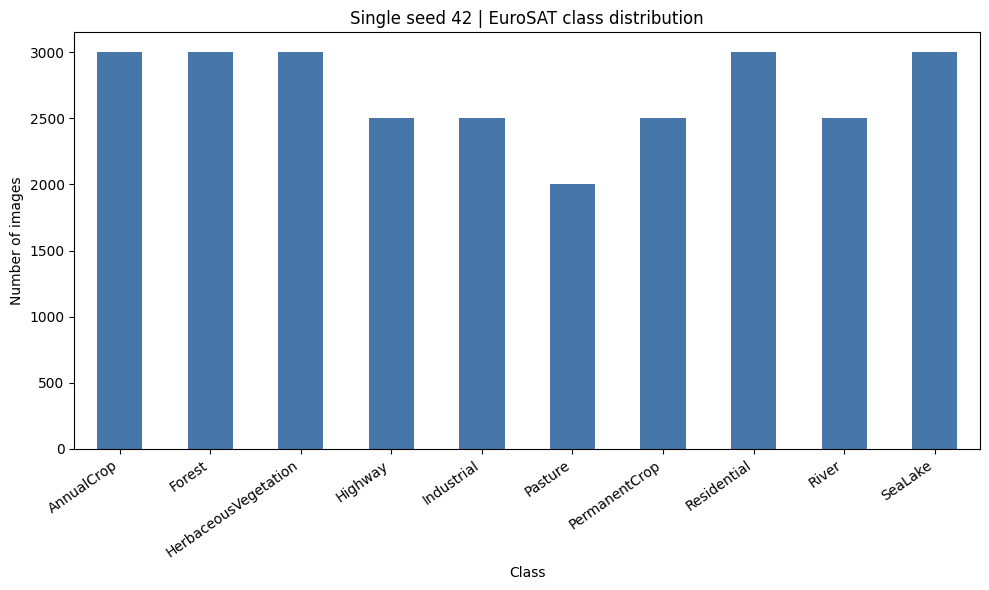

Key takeaway: in this EuroSAT dataset, class counts range from 2000 to 3000; the imbalance ratio is 1.50.


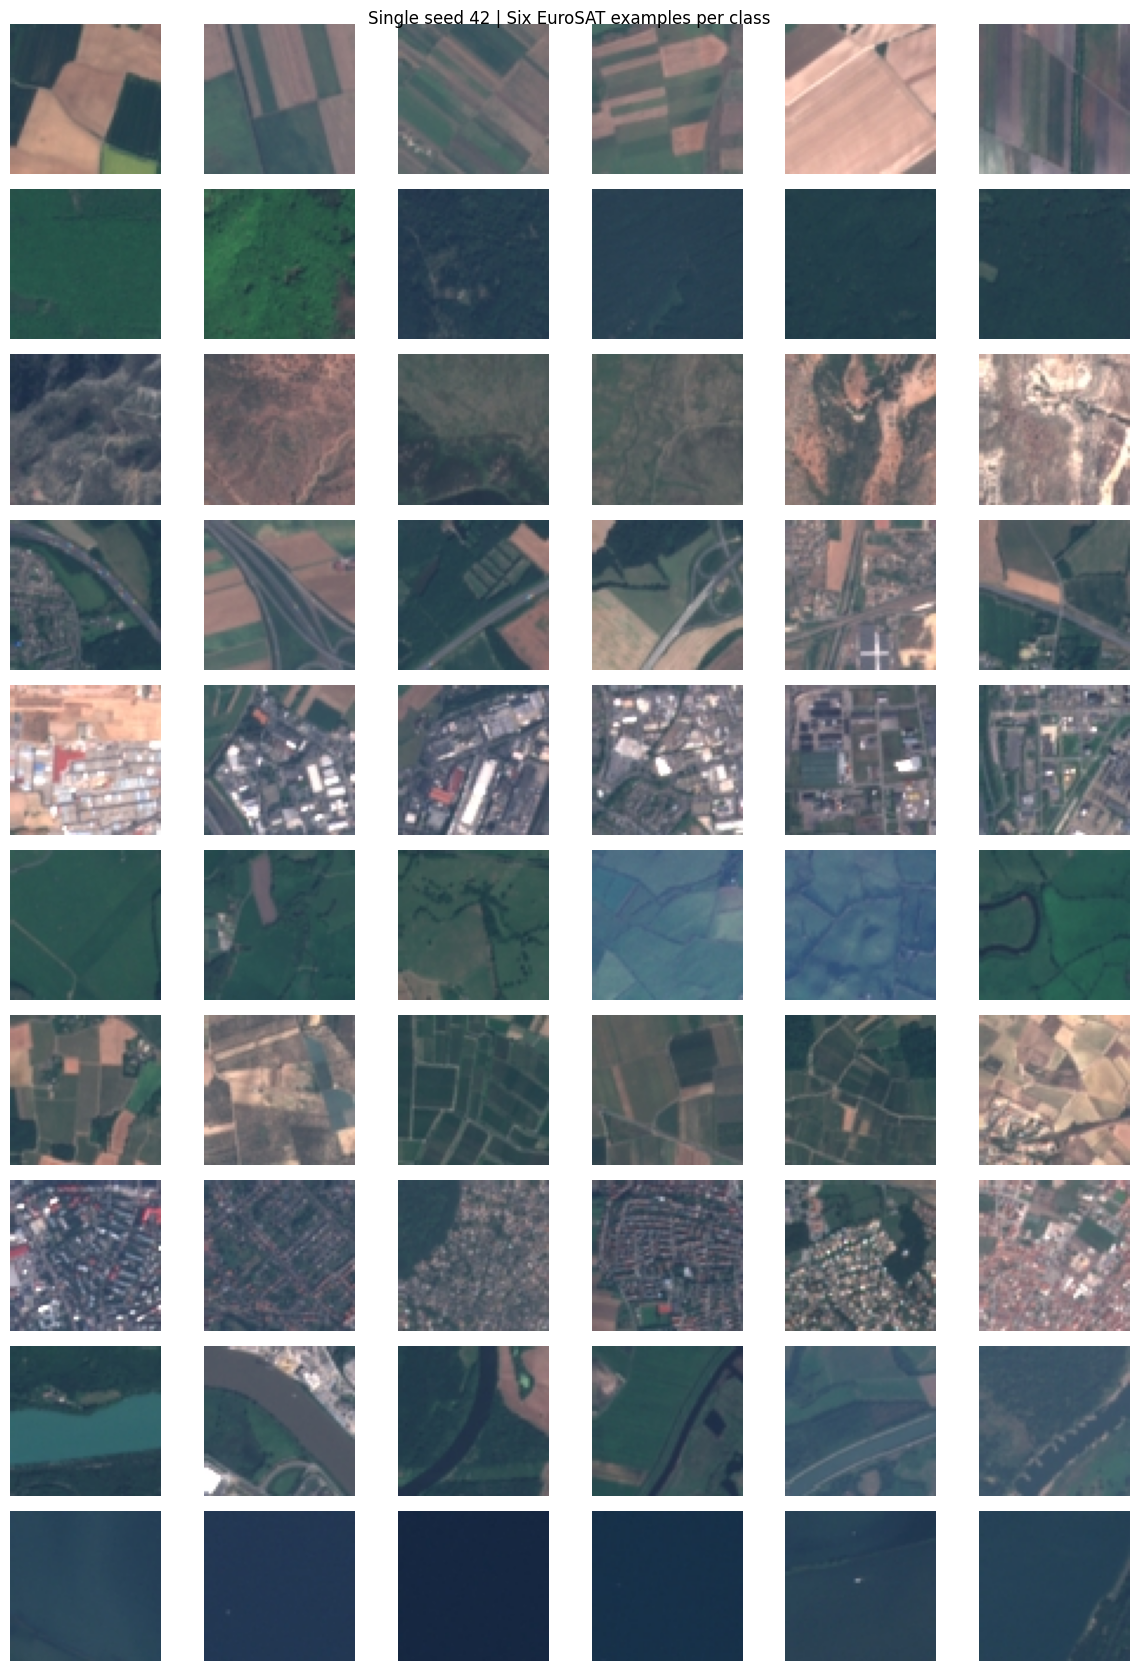

Key takeaway: the grid makes within-class diversity and visually similar class boundaries easy to inspect.
Full-dataset RGB mean: [0.3444, 0.3803, 0.4078]
Full-dataset RGB standard deviation: [0.2027, 0.1369, 0.1156]
Spatial leakage caveat: random splits can place neighbouring patches in different splits and inflate scores. These test results do NOT demonstrate generalisation to new geographic locations.


In [ ]:
# Try torchvision's dataset wrapper first, then use a manually extracted ImageFolder as a clear fallback.
try:
    dataset = torchvision.datasets.EuroSAT(root=str(DATA_DIR), download=True)
except Exception as dataset_error:
    print("Automatic EuroSAT download/loading failed:", repr(dataset_error))
    print("Download EuroSAT_RGB.zip from https://zenodo.org/records/7711810 and unzip its ten class folders under", DATA_DIR)
    candidates = [DATA_DIR / "EuroSAT_RGB", DATA_DIR / "EuroSAT", DATA_DIR / "eurosat", DATA_DIR]
    image_root = next((path for path in candidates if path.exists() and any(child.is_dir() for child in path.iterdir())), None)
    if image_root is None:
        raise RuntimeError("No extracted class folders found. Follow the manual-download instructions above.")
    dataset = torchvision.datasets.ImageFolder(root=str(image_root))

# Assert the expected alphabetical labels and exact dataset counts before deriving any split.
class_names = list(dataset.classes)
assert class_names == CONFIG["class_names"], f"Label order mismatch: expected {CONFIG['class_names']}, found {class_names}"
targets = np.asarray(dataset.targets, dtype=np.int64)
assert len(dataset) == CONFIG["expected_dataset_size"], f"Expected {CONFIG['expected_dataset_size']} images, found {len(dataset)}"
class_counts = {name: int(np.sum(targets == idx)) for idx, name in enumerate(class_names)}
assert class_counts == CONFIG["expected_class_counts"], f"Class-count mismatch: {class_counts}"

# Hash each decoded RGB image and check that every file can be opened successfully.
image_hashes = []
corrupt_paths = []
relative_paths = []
dataset_root = Path(dataset.root)
for image_path, label in tqdm(dataset.samples, desc="Checking image integrity"):
    path = Path(image_path)
    try:
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("RGB"), dtype=np.uint8)
        image_hashes.append(hashlib.sha256(pixels.tobytes()).hexdigest())
        relative_paths.append(path.relative_to(dataset_root).as_posix())
    except Exception:
        corrupt_paths.append(str(path))
        image_hashes.append("")
        relative_paths.append(path.relative_to(dataset_root).as_posix())
assert not corrupt_paths, f"Found corrupt image files: {corrupt_paths[:10]}"
print(f"Corrupt image files: {len(corrupt_paths)}")

# Hash the sorted relative path and label list so a copied dataset has the same manifest.
manifest_items = sorted(f"{path}:{int(label)}" for path, label in zip(relative_paths, targets))
manifest_hash = hashlib.sha256("\n".join(manifest_items).encode("utf-8")).hexdigest()
image_content_items = sorted(f"{path}:{int(label)}:{digest}" for path, label, digest in zip(relative_paths, targets, image_hashes))
image_content_hash = hashlib.sha256("\n".join(image_content_items).encode("utf-8")).hexdigest()
manifest = {"number_of_images": len(dataset), "class_names": class_names, "sorted_relative_path_label_sha256": manifest_hash, "seed": CONFIG["seed"], "split_ratios": CONFIG["split_ratios"]}

# A completed smoke test is useful, but its marker is advisory and never blocks the requested full run.
quicktest_record = None
quicktest_match = False
if not CONFIG["quick_test"]:
    quicktest_path = BASE_DIR / "outputs_quicktest" / "quicktest_passed.json"
    if not quicktest_path.exists():
        print(f"WARNING: no QUICK_TEST marker at {quicktest_path}; continuing with the full run.")
    else:
        try:
            quicktest_record = json.loads(quicktest_path.read_text(encoding="utf-8"))
            expected_quicktest = {"passed": True, "manifest_hash": manifest_hash, "seed": CONFIG["seed"], "training_code_version": CONFIG["training_code_version"]}
            quicktest_match = all(quicktest_record.get(key) == value for key, value in expected_quicktest.items())
            if quicktest_match:
                print("Full-run preflight: matching QUICK_TEST marker found.")
            else:
                print("WARNING: QUICK_TEST marker is stale or belongs to a different dataset, seed, or code version; continuing with the full run.")
        except Exception as quicktest_error:
            print(f"WARNING: QUICK_TEST marker could not be read ({quicktest_error}); continuing with the full run.")

split_path = OUTPUT_DIR / "split_indices.json"

# Convert configured ratios to exact integer counts before calling sklearn.
split_names = ("train", "validation", "test")
split_ratios = CONFIG["split_ratios"]
assert set(split_ratios) == set(split_names), f"Split ratio keys must be {split_names}."
assert all(0 < split_ratios[name] < 1 for name in split_names), "Every split ratio must be between zero and one."
assert math.isclose(sum(split_ratios.values()), 1.0, rel_tol=0, abs_tol=1e-9), f"Split ratios must sum to 1.0; found {split_ratios}."
decimal_ratios = {name: Decimal(str(split_ratios[name])) for name in split_names}
ratio_total = sum(decimal_ratios.values())
exact_split_sizes = {name: decimal_ratios[name] / ratio_total * len(dataset) for name in split_names}
expected_split_sizes = {name: int(value) for name, value in exact_split_sizes.items()}
remaining_count = len(dataset) - sum(expected_split_sizes.values())
remainder_order = sorted(split_names, key=lambda name: exact_split_sizes[name] - expected_split_sizes[name], reverse=True)
for name in remainder_order[:remaining_count]:
    expected_split_sizes[name] += 1

# Recreate the deterministic stratified split from the configured seed when its cache is invalid.
def create_stratified_split():
    all_indices = np.arange(len(dataset), dtype=np.int64)
    train_idx, remainder_idx = train_test_split(all_indices, train_size=expected_split_sizes["train"], random_state=CONFIG["seed"], stratify=targets)
    val_idx, test_idx = train_test_split(remainder_idx, test_size=expected_split_sizes["test"], random_state=CONFIG["seed"], stratify=targets[remainder_idx])
    return {"train": train_idx, "validation": val_idx, "test": test_idx}

canonical_split_indices = create_stratified_split()

# Reject malformed, incomplete, overlapping, or non-canonical arrays before using a saved split.
def validate_split_indices(candidate):
    if not isinstance(candidate, dict) or set(candidate) != set(split_names):
        raise ValueError(f"split arrays must contain exactly {split_names}.")
    validated = {}
    for name in split_names:
        values = np.asarray(candidate[name])
        if values.ndim != 1 or not np.issubdtype(values.dtype, np.integer):
            raise ValueError(f"{name} indices must be a one-dimensional integer array.")
        values = values.astype(np.int64, copy=False)
        if len(values) != expected_split_sizes[name]:
            raise ValueError(f"{name} contains {len(values)} indices; expected {expected_split_sizes[name]} from CONFIG split_ratios.")
        if np.any(values < 0) or np.any(values >= len(dataset)):
            raise ValueError(f"{name} contains an index outside [0, {len(dataset) - 1}].")
        validated[name] = values
    combined = np.concatenate([validated[name] for name in split_names])
    if len(np.unique(combined)) != len(dataset) or not np.array_equal(np.sort(combined), np.arange(len(dataset))):
        raise ValueError("split arrays must be disjoint and cover every dataset index exactly once.")
    for name in split_names:
        if not np.array_equal(np.sort(validated[name]), np.sort(canonical_split_indices[name])):
            raise ValueError(f"{name} membership does not match the deterministic stratified split for seed {CONFIG['seed']}.")
    return validated

# Keep a genuine manifest mismatch as a hard stop, but safely rebuild invalid derived indices.
split_indices = None
split_cache_problem = None
if split_path.exists():
    try:
        saved_split = json.loads(split_path.read_text(encoding="utf-8"))
    except Exception as split_error:
        saved_split = None
        split_cache_problem = f"the JSON could not be read ({split_error})"
    if isinstance(saved_split, dict) and "manifest" in saved_split and saved_split["manifest"] != manifest:
        raise RuntimeError(f"Stale split file: {split_path} does not match the freshly built dataset manifest. Delete that file and rerun this section.")
    if split_cache_problem is None:
        if not isinstance(saved_split, dict) or saved_split.get("manifest") != manifest:
            split_cache_problem = "the cache is missing a valid matching manifest"
        else:
            try:
                split_indices = validate_split_indices({name: saved_split[name] for name in split_names})
                print("Loaded and validated matching stratified split indices from", split_path)
            except (KeyError, TypeError, ValueError) as split_error:
                split_cache_problem = str(split_error)

if split_indices is None:
    if split_cache_problem:
        print(f"Cached split indices are invalid ({split_cache_problem}); rebuilding them deterministically from seed {CONFIG['seed']}.")
    split_indices = canonical_split_indices
    split_payload = {"manifest": manifest, **{name: values.tolist() for name, values in split_indices.items()}}
    temporary_split_path = split_path.with_name(split_path.name + ".tmp")
    temporary_split_path.write_text(json.dumps(split_payload, indent=2), encoding="utf-8")
    temporary_split_path.replace(split_path)

# Verify sizes, complete disjoint coverage, canonical membership, and class counts.
assert {name: len(split_indices[name]) for name in split_names} == expected_split_sizes
assert len(np.unique(np.concatenate([split_indices[name] for name in split_names]))) == len(dataset)
for name in split_names:
    assert np.array_equal(np.bincount(targets[split_indices[name]], minlength=len(class_names)), np.bincount(targets[canonical_split_indices[name]], minlength=len(class_names)))

# Fingerprint actual split membership so checkpoints cannot cross a changed split implementation.
split_membership_items = [f"{name}:{int(index)}" for name in split_names for index in np.sort(split_indices[name])]
split_indices_hash = hashlib.sha256("\n".join(split_membership_items).encode("utf-8")).hexdigest()

split_rows = []
for name, values in split_indices.items():
    counts = np.bincount(targets[values], minlength=len(class_names))
    split_rows.append({"split": name, "images": len(values), **{class_names[i]: int(counts[i]) for i in range(len(class_names))}})
split_table = pd.DataFrame(split_rows).set_index("split")
print("Full split counts:", {name: len(values) for name, values in split_indices.items()})
display(Markdown(f"### {TABLE_BANNER} — per-class split counts"))
display(split_table)

# Count duplicate raster images shared across each pair of splits without deleting any samples.
hash_sets = {name: set(image_hashes[index] for index in values) for name, values in split_indices.items()}
duplicate_pair_counts = {}
for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    shared_hashes = hash_sets[left] & hash_sets[right]
    shared_hashes.discard("")
    duplicate_pair_counts[f"{left}–{right}"] = len(shared_hashes)
print("Exact duplicate image hashes shared across split pairs:", duplicate_pair_counts)
unique_image_hash_count = len(set(image_hashes) - {""})
print(f"Distinct decoded image hashes across the full dataset: {unique_image_hash_count}.")

# Reuse the uint8 cache only when manifest, tensor type, shape, and pixel dtype match.
tensor_cache_path = DATA_DIR / "eurosat_uint8.pt"
cached = None
if tensor_cache_path.exists():
    try:
        cached = torch.load(tensor_cache_path, map_location="cpu")
    except Exception as cache_error:
        print("Cached uint8 tensor could not be read; rebuilding it:", repr(cache_error))
cached_images = cached.get("images") if isinstance(cached, dict) else None
expected_tensor_shape = (len(dataset), 3, 64, 64)
cache_is_valid = isinstance(cached, dict) and cached.get("manifest_hash") == manifest_hash and cached.get("image_content_hash") == image_content_hash
cache_is_valid = cache_is_valid and torch.is_tensor(cached_images) and tuple(cached_images.shape) == expected_tensor_shape and cached_images.dtype == torch.uint8
if not cache_is_valid:
    if cached is not None:
        print("Cached image tensor has a stale manifest or invalid type/shape/dtype; rebuilding it.")
    image_tensors = []
    for image_path, _ in tqdm(dataset.samples, desc="Caching RGB images"):
        with Image.open(image_path) as image:
            image_array = np.asarray(image.convert("RGB"), dtype=np.uint8).copy()
        image_tensors.append(torch.from_numpy(image_array).permute(2, 0, 1))
    cached = {"images": torch.stack(image_tensors), "manifest_hash": manifest_hash, "image_content_hash": image_content_hash}
    temporary_tensor_cache_path = tensor_cache_path.with_name(tensor_cache_path.name + ".tmp")
    torch.save(cached, temporary_tensor_cache_path)
    temporary_tensor_cache_path.replace(tensor_cache_path)
images_u8 = cached["images"]
assert tuple(images_u8.shape) == expected_tensor_shape and images_u8.dtype == torch.uint8
print(f"Cached tensor shape: {tuple(images_u8.shape)}; storage: {tensor_cache_path.stat().st_size / (1024**2):.1f} MB")

# In quick-test mode, allocate the configured examples per class across splits by their ratios.
active_splits = {name: values.copy() for name, values in split_indices.items()}
if CONFIG["quick_test"]:
    quick_total = int(CONFIG["quick_test_images_per_class"])
    quick_exact_sizes = {name: decimal_ratios[name] / ratio_total * quick_total for name in split_names}
    quotas = {name: int(value) for name, value in quick_exact_sizes.items()}
    leftover = quick_total - sum(quotas.values())
    if quick_total < 1:
        raise ValueError("QUICK_TEST needs at least one image per class; increase quick_test_images_per_class.")
    remainder_order = sorted(split_names, key=lambda name: -(quick_exact_sizes[name] - quotas[name]))
    for name in remainder_order[:leftover]:
        quotas[name] += 1
    if any(quota < 1 for quota in quotas.values()):
        raise ValueError("QUICK_TEST needs at least one image per class in every split; increase quick_test_images_per_class or adjust split_ratios.")
    active_splits = {name: [] for name in split_names}
    for class_id in range(len(class_names)):
        for split_name in split_names:
            candidates = split_indices[split_name][targets[split_indices[split_name]] == class_id]
            if len(candidates) < quotas[split_name]:
                raise ValueError(f"QUICK_TEST needs {quotas[split_name]} {split_name} samples for class {class_names[class_id]}, but only {len(candidates)} are available.")
            active_splits[split_name].extend(candidates[:quotas[split_name]].tolist())
    active_splits = {name: np.asarray(values, dtype=np.int64) for name, values in active_splits.items()}
    print(f"QUICK TEST subset per class: {quotas}; {quick_total} images total.")

# Fingerprint the actual training, validation, and test indices used by this run.
active_split_items = [f"{name}:{int(index)}" for name in split_names for index in np.sort(active_splits[name])]
active_split_indices_hash = hashlib.sha256("\n".join(active_split_items).encode("utf-8")).hexdigest()

# Show class balance and the RGB sample patches so label or loading problems are visible.
class_plot = pd.Series(class_counts).reindex(class_names)
fig, ax = plt.subplots(figsize=CONFIG["figure_size"])
class_plot.plot(kind="bar", ax=ax, color="#4776a8")
ax.set_title(figure_title("EuroSAT class distribution"))
ax.set_ylabel("Number of images")
ax.set_xlabel("Class")
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_distribution.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print(f"Key takeaway: in this EuroSAT dataset, class counts range from {min(class_counts.values())} to {max(class_counts.values())}; the imbalance ratio is {max(class_counts.values()) / min(class_counts.values()):.2f}.")

# Display six fixed-seed examples for every class to inspect labels and patch content.
fig, axes = plt.subplots(len(class_names), CONFIG["sample_grid_per_class"], figsize=(12, 17))
for class_id, class_name in enumerate(class_names):
    candidates = np.flatnonzero(targets == class_id)
    chosen = np.random.default_rng(CONFIG["seed"] + class_id).choice(candidates, CONFIG["sample_grid_per_class"], replace=False)
    for column, image_index in enumerate(chosen):
        axes[class_id, column].imshow(images_u8[image_index].permute(1, 2, 0).numpy())
        axes[class_id, column].axis("off")
        if column == 0:
            axes[class_id, column].set_ylabel(class_name, fontsize=8)
fig.suptitle(figure_title("Six EuroSAT examples per class"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "sample_grid.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print("Key takeaway: the grid makes within-class diversity and visually similar class boundaries easy to inspect.")

# Summarise the image RGB channels over the full decoded dataset, using [0, 1] values.
channel_values = images_u8.float() / 255.0
channel_mean = channel_values.mean(dim=(0, 2, 3)).tolist()
channel_std = channel_values.std(dim=(0, 2, 3), unbiased=False).tolist()
print("Full-dataset RGB mean:", [round(value, 4) for value in channel_mean])
print("Full-dataset RGB standard deviation:", [round(value, 4) for value in channel_std])
del channel_values
gc.collect()

# Explain the main leakage caveat before any model fitting.
print("Spatial leakage caveat: random splits can place neighbouring patches in different splits and inflate scores. These test results do NOT demonstrate generalisation to new geographic locations.")


### How to read the class distribution

Bar height is the number of source images in each class. A modest count difference is not itself a model bias result; the later per-class metrics show how the evaluated pipelines behave.

### How to read the sample grid

Rows correspond to labels and columns show different source patches. Look for within-class variation and visual overlap between labels before interpreting confusion pairs.


## Section 3: Pre-processing and augmentation

**Concept box.** Each model gets the mean, standard deviation and interpolation setting from its own pretrained configuration. We resize every full 64×64 patch to 224×224 and deliberately skip centre crops. Expect a printed preprocessing card and an augmentation example. A common mistake is to reuse one model's normalisation settings for another.

Pipeline: `uint8 64×64 → float [1] → training-only geometric/brightness/contrast changes → 224×224 resize using that checkpoint's interpolation → that model's own normalisation`.

The input size is fixed to 224 for a fair, manageable common interface. BiT's checkpoint configuration documents a default of 448; 224 is a deliberate deviation. No centre crop is used for any model because these small patches are fully informative and cropping would remove border pixels. ViT sees 224/16 = 14 patches on each side, or 196 image patches.

| Operation | Why | Train | Validation | Test |
|---|---|---:|---:|---:|
| RGB conversion and uint8 cache | Stable, compact source representation | Yes | Yes | Yes |
| Bicubic/bilinear checkpoint resize | Respect each checkpoint's interpolation | Yes | Yes | Yes |
| Checkpoint-specific normalisation | Match pretrained input statistics | Yes | Yes | Yes |
| Horizontal/vertical flips and 90° rotations | Satellite patches have no canonical orientation | Yes | No | No |
| ±10% brightness/contrast jitter | Add mild appearance variation while retaining colour meaning | Yes | No | No |
| Hue jitter | Not used because colour carries land-cover information | No | No | No |


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

### Single-seed experiment — preprocessing card

,input size used,checkpoint default,mean,std,interpolation,crop
model,,,,,,
vit_base_patch16_224.augreg_in21k_ft_in1k,224,224,"[0.5, 0.5, 0.5]","[0.5, 0.5, 0.5]",bicubic,none
resnetv2_50x1_bit.goog_in21k_ft_in1k,224,448,"[0.5, 0.5, 0.5]","[0.5, 0.5, 0.5]",bilinear,none


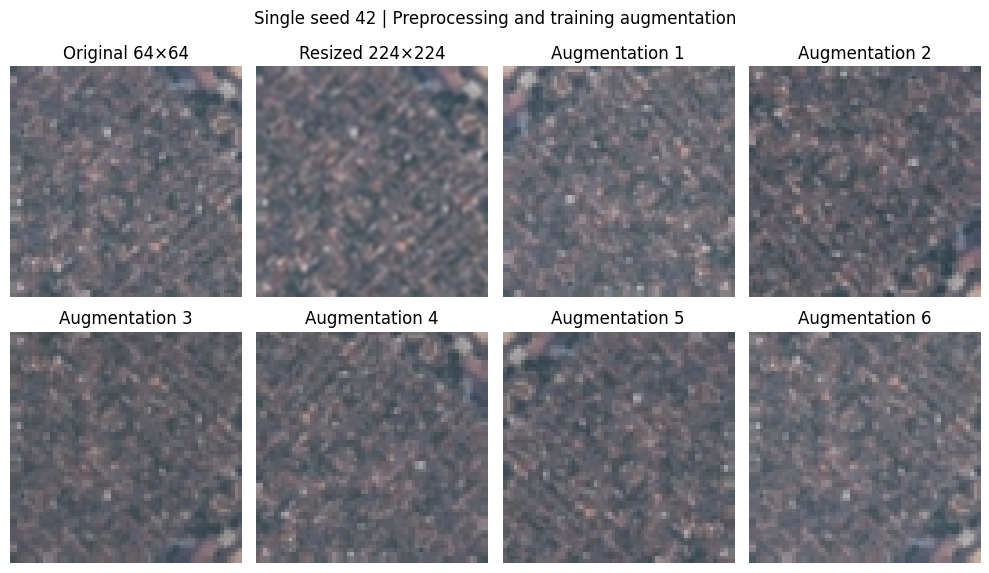

Key takeaway: orientation changes are visible while colour is retained; resize preserves the full patch without cropping.


85173

In [ ]:
# Create pretrained timm models only long enough to read their checkpoint-owned preprocessing metadata.
def create_timm_model(model_name):
    try:
        return timm.create_model(model_name, pretrained=True, num_classes=len(class_names))
    except Exception as model_error:
        print("Pretrained checkpoint loading failed:", repr(model_error))
        print("Run this notebook on Colab and copy outputs/checkpoints to this machine.")
        raise

def interpolation_name(value):
    # Convert enums or strings into the two interpolation modes supported by tensor resizing here.
    name = str(value).lower()
    if "bicubic" in name:
        return "bicubic"
    if "bilinear" in name:
        return "bilinear"
    print(f"Checkpoint interpolation {value!r} is not bicubic/bilinear; using bilinear as a supported fallback.")
    return "bilinear"

def timm_preprocessing(model):
    # Resolve the checkpoint's mean, standard deviation, interpolation and documented default image size.
    data_config = timm.data.resolve_data_config({}, model=model)
    default_size = int(data_config["input_size"][-1])
    return {"mean": list(data_config["mean"]), "std": list(data_config["std"]), "interpolation": interpolation_name(data_config["interpolation"]), "default_size": default_size}

# Read metadata for ViT and CNN from their own pretrained configurations.
preprocessing = {}
for key, model_name in (("E1", CONFIG["vit_model"]), ("E2", CONFIG["cnn_model"])):
    temporary_model = create_timm_model(model_name)
    preprocessing[key] = timm_preprocessing(temporary_model)
    del temporary_model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Show the actual settings used, including each checkpoint's documented default and the no-crop choice.
preprocessing_rows = []
for key, values in preprocessing.items():
    model_name = CONFIG["vit_model"] if key == "E1" else CONFIG["cnn_model"]
    preprocessing_rows.append({"model": model_name, "input size used": CONFIG["image_size"], "checkpoint default": values["default_size"], "mean": values["mean"], "std": values["std"], "interpolation": values["interpolation"], "crop": "none"})
preprocessing_table = pd.DataFrame(preprocessing_rows).set_index("model")
display(Markdown(f"### {TABLE_BANNER} — preprocessing card"))
display(preprocessing_table)

# Implement per-image flips, quarter-turns and mild brightness/contrast jitter on GPU tensors.
def augment_batch(batch):
    batch = batch.clone()
    batch_size = batch.shape[0]
    flip_lr = torch.rand(batch_size, device=batch.device) < 0.5
    flip_ud = torch.rand(batch_size, device=batch.device) < 0.5
    batch[flip_lr] = torch.flip(batch[flip_lr], dims=[3])
    batch[flip_ud] = torch.flip(batch[flip_ud], dims=[2])
    rotations = torch.randint(0, 4, (batch_size,), device=batch.device)
    for turns in range(1, 4):
        selected = rotations == turns
        batch[selected] = torch.rot90(batch[selected], k=turns, dims=[2, 3])
    strength = CONFIG["augmentation_strength"]
    brightness = 1.0 + (torch.rand(batch_size, 1, 1, 1, device=batch.device) * 2 - 1) * strength
    contrast = 1.0 + (torch.rand(batch_size, 1, 1, 1, device=batch.device) * 2 - 1) * strength
    per_image_mean = batch.mean(dim=(1, 2, 3), keepdim=True)
    return (((batch - per_image_mean) * contrast + per_image_mean) * brightness).clamp(0, 1)

# Convert a batch, apply an optional 64×64 corruption or train augmentation, resize, and normalise.
def prepare_batch(images, model_key, training=False, corruption=None):
    batch = images.to(device=device, dtype=torch.float32, non_blocking=True) / 255.0
    if corruption == "blur":
        coords = torch.arange(CONFIG["blur_kernel_size"], device=device, dtype=torch.float32) - (CONFIG["blur_kernel_size"] - 1) / 2
        kernel_1d = torch.exp(-(coords ** 2) / (2 * CONFIG["blur_sigma"] ** 2))
        kernel_1d = kernel_1d / kernel_1d.sum()
        kernel_2d = torch.outer(kernel_1d, kernel_1d)
        kernel = kernel_2d.expand(3, 1, -1, -1)
        padding = CONFIG["blur_kernel_size"] // 2
        batch = F.conv2d(F.pad(batch, (padding, padding, padding, padding), mode="reflect"), kernel, groups=3)
    elif corruption == "brightness_x0.6":
        batch = (batch * CONFIG["brightness_factors"][0]).clamp(0, 1)
    elif corruption == "brightness_x1.4":
        batch = (batch * CONFIG["brightness_factors"][1]).clamp(0, 1)
    elif corruption == "haze":
        batch = (batch * (1 - CONFIG["haze_alpha"]) + CONFIG["haze_alpha"] * CONFIG["haze_value"]).clamp(0, 1)
    if training:
        batch = augment_batch(batch)
    batch = F.interpolate(batch, size=(CONFIG["image_size"], CONFIG["image_size"]), mode=preprocessing[model_key]["interpolation"], align_corners=False)
    batch = batch.clamp(0, 1)
    mean = torch.tensor(preprocessing[model_key]["mean"], device=device).view(1, 3, 1, 1)
    std = torch.tensor(preprocessing[model_key]["std"], device=device).view(1, 3, 1, 1)
    return (batch - mean) / std

# Show one source image, its 224-pixel resize, and six independently augmented views.
example_index = int(active_splits["train"][0])
example = images_u8[example_index:example_index + 1].float().to(device) / 255.0
augmented = augment_batch(example.repeat(6, 1, 1, 1))
resized_example = F.interpolate(example, size=(CONFIG["image_size"], CONFIG["image_size"]), mode=preprocessing["E1"]["interpolation"], align_corners=False).clamp(0, 1)
fig, axes = plt.subplots(2, 4, figsize=CONFIG["figure_size"])
axes[0, 0].imshow(images_u8[example_index].permute(1, 2, 0).numpy())
axes[0, 0].set_title("Original 64×64")
axes[0, 1].imshow(resized_example[0].permute(1, 2, 0).cpu().numpy())
axes[0, 1].set_title("Resized 224×224")
for index, axis in enumerate(axes.flat[2:]):
    axis.imshow(augmented[index].permute(1, 2, 0).cpu().numpy())
    axis.set_title(f"Augmentation {index + 1}")
for axis in axes.flat:
    axis.axis("off")
fig.suptitle(figure_title("Preprocessing and training augmentation"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "preprocessing_augmentation.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print("Key takeaway: orientation changes are visible while colour is retained; resize preserves the full patch without cropping.")
del example, augmented, resized_example
gc.collect()


### How to read the augmentation figure

The first two panels show the source patch and its full-frame resize. The other panels are independent training-only transformations. They illustrate the allowed geometry and mild brightness/contrast changes; validation and test images are never augmented.


## Section 4: Model selection and implementation [Rubric: 25%]

**Concept box.** Both pipelines start from pretrained weights and are fine-tuned on EuroSAT. The project brief’s vision-transformer route is met by the ViT; the CNN gives a useful conventional baseline. Expect model details, resource settings, epoch logs, validation curves and checkpoints. This is a comparison of complete pretrained pipelines, not a pure architecture experiment.

| Pipeline | Rationale | Pretraining | Main limitation |
|---|---|---|---|
| ViT-B/16 [2] | Applies a modern Vision Transformer to the land-cover task | ImageNet-21k pretraining followed by ImageNet-1k fine-tuning | About 86M parameters; uses global token attention |
| BiT ResNet-50 [3,5,6] | Provides a pretrained residual CNN baseline with GroupNorm | Big Transfer supervised ImageNet-21k pretraining followed by ImageNet-1k fine-tuning | About 25.5M parameters; this run uses 224-pixel inputs although the checkpoint default is 448 |

ViT and CNN differ in architecture, parameter count, pretraining details, head initialization and checkpoint input defaults. Results therefore describe these two pipelines, not a causal architecture effect.

**Training choices and learning curves.** The ViT uses 6 epochs at a learning rate of 3×10⁻⁵, while the CNN uses 8 epochs at 1×10⁻⁴: the larger transformer is adapted with a smaller update and shorter run, while the CNN uses a higher rate and more epochs. These are practical model-specific recipes, not a search proving either setting optimal. With 10 classes and label smoothing of 0.1, the smoothed target has entropy of about 0.50 nats, so a training-loss plateau near 0.5 is expected and is not, by itself, evidence of underfitting. Use this run’s validation curves to determine whether either metric is still rising at the final epoch; treat that as a measured result, not an assumption.

The implementation uses PyTorch [11] and timm [12]. AdamW follows decoupled weight decay [4], and automatic mixed precision is used where supported [8].

**Planning estimate (rough, hardware-dependent; checkpoint downloads add time):** allow about 45–100 minutes per model on a Colab T4, plus setup and final analysis. On an 8 GB university GPU, allow about 1.5–3 hours per model. The feasibility benchmark estimates this run from measured throughput and compares it with the configured time budget; it never changes the recipe automatically.


In [ ]:
# Choose conservative micro-batches from VRAM; CPU quick tests use their own small batch.
model_settings = {}
if torch.cuda.is_available():
    if vram_gb <= 10:
        initial_micro = CONFIG["starting_micro_batches"]["under_or_equal_10_gb"]
    elif vram_gb <= 20:
        initial_micro = CONFIG["starting_micro_batches"]["under_or_equal_20_gb"]
    else:
        initial_micro = CONFIG["starting_micro_batches"]["over_20_gb"]
else:
    initial_micro = CONFIG["quick_test_cpu_batch"]
for key in ("E1", "E2"):
    model_settings[key] = {"micro_batch": initial_micro, "accumulation_steps": math.ceil(CONFIG["effective_batch_size"] / initial_micro), "evaluation_batch": min(CONFIG["evaluation_batch_max"], max(8, initial_micro * 2))}

# Build an SGD-free inference helper used for validation and test; it computes softmax exactly once per batch.
def evaluate_model(model, model_key, indices, corruption=None):
    model.eval()
    probability_parts = []
    label_parts = []
    batch_size = model_settings[model_key]["evaluation_batch"]
    with torch.inference_mode():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]
            raw = images_u8[batch_indices]
            inputs = prepare_batch(raw, model_key, corruption=corruption)
            with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = model(inputs)
            probability_parts.append(torch.softmax(logits.float(), dim=1).cpu())
            label_parts.append(torch.as_tensor(targets[batch_indices], dtype=torch.long))
    return torch.cat(probability_parts).numpy(), torch.cat(label_parts).numpy()

# Count trainable parameters directly from each instantiated model.
def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

# Execute a temporary training benchmark, then discard every temporary state before the real run.
def smoke_benchmark(model_key, model_name, headroom_retry=True):
    settings = model_settings[model_key]
    benchmark_rows = []
    while True:
        temporary_model = None
        temporary_optimizer = None
        temporary_scaler = None
        batch_tensor = None
        inputs = labels = loss = logits = None
        try:
            temporary_model = create_timm_model(model_name).to(device)
            temporary_model.train()
            smoke_lr = CONFIG["learning_rates"]["cnn_fallback"] if model_key == "E2" and CONFIG["cnn_model"] == CONFIG["cnn_fallback_model"] else CONFIG["learning_rates"][model_key]
            temporary_optimizer = torch.optim.AdamW(temporary_model.parameters(), lr=smoke_lr, weight_decay=CONFIG["weight_decay"])
            temporary_scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
            torch.cuda.reset_peak_memory_stats() if torch.cuda.is_available() else None
            started = time.perf_counter()
            train_indices = active_splits["train"]
            for step in range(CONFIG["smoke_train_steps"]):
                start = (step * settings["micro_batch"]) % max(1, len(train_indices) - settings["micro_batch"])
                selected = train_indices[start:start + settings["micro_batch"]]
                batch_tensor = images_u8[selected]
                labels = torch.as_tensor(targets[selected], device=device)
                inputs = prepare_batch(batch_tensor, model_key)
                temporary_optimizer.zero_grad(set_to_none=True)
                with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                    loss = F.cross_entropy(temporary_model(inputs), labels)
                temporary_scaler.scale(loss).backward()
                temporary_scaler.unscale_(temporary_optimizer)
                torch.nn.utils.clip_grad_norm_(temporary_model.parameters(), CONFIG["gradient_clip_norm"])
                temporary_scaler.step(temporary_optimizer)
                temporary_scaler.update()
                del inputs, labels, loss
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            train_seconds = max(time.perf_counter() - started, 1e-6)
            temporary_model.eval()
            eval_started = time.perf_counter()
            eval_indices = active_splits["validation"]
            with torch.inference_mode():
                for eval_step in range(CONFIG["smoke_eval_batches"]):
                    start = (eval_step * settings["evaluation_batch"]) % len(eval_indices)
                    selected = eval_indices[start:start + settings["evaluation_batch"]]
                    if len(selected) < settings["evaluation_batch"]:
                        selected = np.resize(selected, settings["evaluation_batch"])
                    batch_tensor = images_u8[selected]
                    inputs = prepare_batch(batch_tensor, model_key)
                    with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                        _ = temporary_model(inputs)
                    del inputs
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            eval_seconds = max(time.perf_counter() - eval_started, 1e-6)
            peak_gb = torch.cuda.max_memory_allocated() / (1024 ** 3) if torch.cuda.is_available() else 0.0
            benchmark_rows.append({"train_images_per_second": CONFIG["smoke_train_steps"] * settings["micro_batch"] / train_seconds, "eval_images_per_second": CONFIG["smoke_eval_batches"] * settings["evaluation_batch"] / eval_seconds, "peak_gb": peak_gb})
            break
        except torch.cuda.OutOfMemoryError:
            print(f"OOM in {model_key} smoke benchmark at micro-batch {settings['micro_batch']}; clearing temporary state and retrying.")
            if temporary_optimizer is not None:
                temporary_optimizer.zero_grad(set_to_none=True)
            gc.collect()
            torch.cuda.empty_cache()
            if settings["micro_batch"] <= CONFIG["minimum_micro_batch"] and settings["evaluation_batch"] <= CONFIG["minimum_micro_batch"]:
                raise RuntimeError("Even micro-batch 2 does not fit. Close other GPU-heavy programs, run on Colab, or choose cnn_model in CONFIG; the notebook will not silently change the model or recipe.")
            if settings["micro_batch"] > CONFIG["minimum_micro_batch"]:
                settings["micro_batch"] = max(CONFIG["minimum_micro_batch"], settings["micro_batch"] // 2)
                settings["accumulation_steps"] *= 2
            settings["evaluation_batch"] = max(CONFIG["minimum_micro_batch"], settings["evaluation_batch"] // 2)
        finally:
            if temporary_optimizer is not None:
                temporary_optimizer.zero_grad(set_to_none=True)
            inputs = labels = loss = logits = batch_tensor = None
            del temporary_model, temporary_optimizer, temporary_scaler, batch_tensor
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
    peak_gb = benchmark_rows[-1]["peak_gb"]
    if headroom_retry and torch.cuda.is_available() and peak_gb > CONFIG["memory_headroom_fraction"] * vram_gb and settings["micro_batch"] > CONFIG["minimum_micro_batch"]:
        print(f"{model_key} smoke peak {peak_gb:.1f} GB exceeds {CONFIG['memory_headroom_fraction']:.0%} of VRAM; halving micro-batch once and repeating with fresh weights.")
        settings["micro_batch"] = max(CONFIG["minimum_micro_batch"], settings["micro_batch"] // 2)
        settings["accumulation_steps"] *= 2
        settings["evaluation_batch"] = max(CONFIG["minimum_micro_batch"], min(settings["evaluation_batch"], settings["micro_batch"] * 2))
        return smoke_benchmark(model_key, model_name, headroom_retry=False)
    return benchmark_rows[-1]

# Measure throughput on a temporary model only; temporary weights and optimiser state never enter training.
benchmarks = {}
if torch.cuda.is_available():
    for key, model_name in (("E1", CONFIG["vit_model"]), ("E2", CONFIG["cnn_model"])):
        benchmarks[key] = smoke_benchmark(key, model_name)
        print(f"{key} settings: {model_settings[key]} | smoke peak allocated: {benchmarks[key]['peak_gb']:.2f} GB")
else:
    print("CPU QUICK TEST settings:", model_settings)

# Estimate epoch training and validation time from measured GPU throughput before committing to the run.
estimated_seconds = {}
if benchmarks:
    for key in ("E1", "E2"):
        epochs = CONFIG["quick_test_epochs"] if CONFIG["quick_test"] else CONFIG["epochs"][key]
        training_time = len(active_splits["train"]) * epochs / benchmarks[key]["train_images_per_second"]
        validation_time = len(active_splits["validation"]) * epochs / benchmarks[key]["eval_images_per_second"]
        final_eval_images = len(active_splits["validation"]) + len(active_splits["test"]) * (1 + len(CONFIG["corruptions"]))
        final_eval_time = final_eval_images / benchmarks[key]["eval_images_per_second"]
        estimated_seconds[key] = training_time + validation_time + final_eval_time
    total_estimated = sum(estimated_seconds.values())
    print("Throughput-based estimate (download/setup excluded):", {key: f"{value/60:.1f} min" for key, value in estimated_seconds.items()}, f"total {total_estimated/3600:.2f} h")
    if total_estimated > CONFIG["time_budget_hours"] * 3600:
        print(f"WARNING: estimated notebook runtime exceeds {CONFIG['time_budget_hours']:.1f} hours. Student options: reduce epochs in CONFIG or run on Colab. No setting has been changed.")
else:
    print("No CUDA throughput estimate is available; CPU quick-test duration is hardware- and download-dependent.")


E1 settings: {'micro_batch': 16, 'accumulation_steps': 4, 'evaluation_batch': 32} | smoke peak allocated: 2.19 GB
E2 settings: {'micro_batch': 16, 'accumulation_steps': 4, 'evaluation_batch': 32} | smoke peak allocated: 1.81 GB
Throughput-based estimate (download/setup excluded): {'E1': '33.3 min', 'E2': '26.1 min'} total 0.99 h


E1 epoch 1 training:   0%|          | 0/1182 [00:00<?, ?it/s]

E1 epoch 1/6: loss 0.8753, val accuracy 0.9659, val macro-F1 0.9642; skipped optimizer steps 1; estimated model time remaining 27.8 min.


E1 epoch 2 training:   0%|          | 0/1182 [00:00<?, ?it/s]

E1 epoch 2/6: loss 0.5670, val accuracy 0.9699, val macro-F1 0.9689; skipped optimizer steps 0; estimated model time remaining 22.2 min.


E1 epoch 3 training:   0%|          | 0/1182 [00:00<?, ?it/s]

...

E2 epoch 7/8: loss 0.5103, val accuracy 0.9864, val macro-F1 0.9859; skipped optimizer steps 0; estimated model time remaining 3.3 min.


E2 epoch 8 training:   0%|          | 0/1182 [00:00<?, ?it/s]

E2 epoch 8/8: loss 0.5064, val accuracy 0.9867, val macro-F1 0.9861; skipped optimizer steps 0; estimated model time remaining 0.0 min.
E2 complete: 23,520,842 trainable parameters; best validation macro-F1 0.9874; checkpoint 89.8 MB.


### Single-seed experiment — model parameters and provenance

,pipeline,total parameters,EuroSAT-trained,pretraining,input size used
0,vit_base_patch16_224.augreg_in21k_ft_in1k,85806346,Yes,ImageNet-21k then ImageNet-1k,224
1,resnetv2_50x1_bit.goog_in21k_ft_in1k,23520842,Yes,ImageNet-21k then ImageNet-1k,224


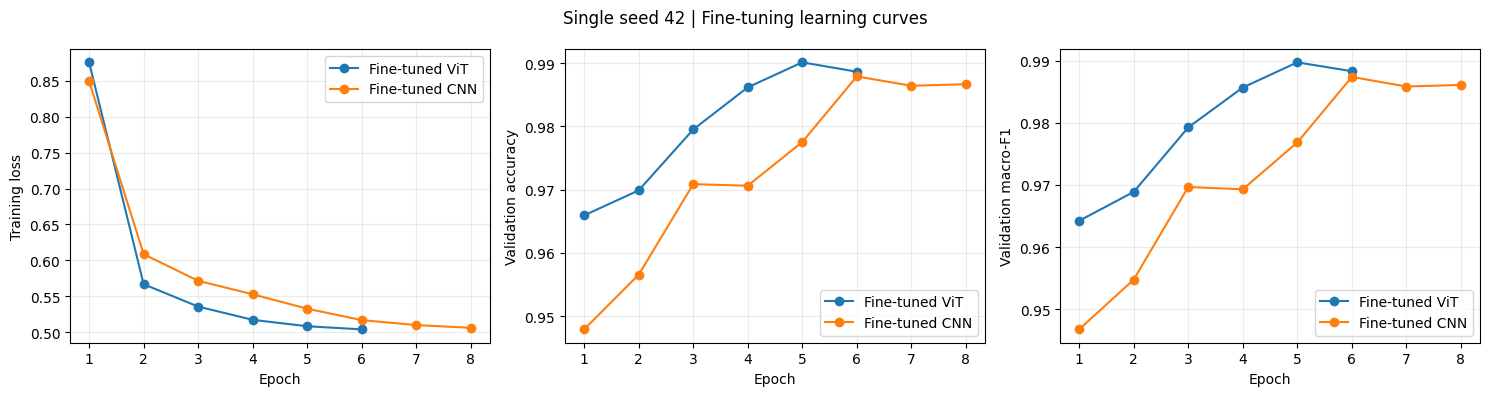

How to spot fit patterns: falling training loss with rising validation macro-F1 is useful learning; falling training loss with flat or falling validation scores can indicate over-fitting.
Key takeaway: in this single-seed run, validation macro-F1 was 0.990 for the ViT pipeline and 0.987 for the CNN pipeline.


In [ ]:
# Build the warm-up plus cosine schedule using optimizer-step counts for the current split and batch settings.
def make_scheduler(optimizer, epochs, steps_per_epoch, warmup_epochs):
    warmup_steps = max(1, warmup_epochs * steps_per_epoch)
    total_steps = max(warmup_steps + 1, epochs * steps_per_epoch)
    def scale(step):
        if step < warmup_steps:
            return float(step + 1) / warmup_steps
        progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
        return 0.5 * (1.0 + math.cos(math.pi * progress))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, scale)

# Train one epoch with random GPU augmentations, accumulation, mixed precision and gradient clipping.
def train_one_epoch(model, model_key, optimizer, scheduler, scaler, criterion, epoch):
    model.train()
    indices = np.random.permutation(active_splits["train"])
    batch_size = model_settings[model_key]["micro_batch"]
    batch_starts = list(range(0, len(indices), batch_size))
    group_size = model_settings[model_key]["accumulation_steps"]
    loss_total = 0.0
    seen = 0
    skipped_optimizer_steps = 0
    for batch_number, start in enumerate(tqdm(batch_starts, desc=f"{model_key} epoch {epoch} training")):
        selected = indices[start:start + batch_size]
        raw = images_u8[selected]
        labels = torch.as_tensor(targets[selected], dtype=torch.long, device=device)
        inputs = prepare_batch(raw, model_key, training=True)
        current_group = min(group_size, len(batch_starts) - (batch_number // group_size) * group_size)
        with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            logits = model(inputs)
            loss = criterion(logits, labels)
        scaler.scale(loss / current_group).backward()
        should_step = ((batch_number + 1) % group_size == 0) or (batch_number + 1 == len(batch_starts))
        if should_step:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG["gradient_clip_norm"])
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            optimizer_step_ran = (not scaler.is_enabled()) or (scaler.get_scale() >= scale_before)
            optimizer.zero_grad(set_to_none=True)
            if optimizer_step_ran:
                scheduler.step()
            else:
                skipped_optimizer_steps += 1
        loss_total += float(loss.detach()) * len(selected)
        seen += len(selected)
        del raw, labels, inputs, logits, loss
    return loss_total / max(1, seen), skipped_optimizer_steps

# Create a stable hash of the settings that affect checkpoint compatibility.
def config_fingerprint(model_key, model_name, learning_rate, epochs):
    settings = {"model_name": model_name, "learning_rate": learning_rate, "epochs": epochs, "batch_settings": model_settings[model_key], "image_size": CONFIG["image_size"], "seed": CONFIG["seed"], "weight_decay": CONFIG["weight_decay"], "warmup_epochs": CONFIG["warmup_epochs"], "label_smoothing": CONFIG["label_smoothing"], "gradient_clip_norm": CONFIG["gradient_clip_norm"], "augmentation_strength": CONFIG["augmentation_strength"], "use_amp": use_amp, "device_type": device.type, "preprocessing": preprocessing[model_key], "dataset_manifest_hash": manifest_hash, "image_content_hash": image_content_hash, "split_indices_hash": split_indices_hash, "active_split_indices_hash": active_split_indices_hash, "training_code_version": CONFIG["training_code_version"]}
    return hashlib.sha256(json.dumps(settings, sort_keys=True).encode("utf-8")).hexdigest(), settings

# Save current experiment results after every model so a later interruption retains completed work.
results = {"manifest": manifest, "run_label": RUN_LABEL, "experiments": {}, "split_indices_hash": split_indices_hash, "active_split_indices_hash": active_split_indices_hash, "image_content_hash": image_content_hash}
results_path = OUTPUT_DIR / "results.json"
if results_path.exists() and not CONFIG["rerun"]:
    try:
        previous_results = json.loads(results_path.read_text(encoding="utf-8"))
        if previous_results.get("manifest") == manifest:
            results.update(previous_results)
    except Exception as read_error:
        print("Existing results.json could not be reused:", repr(read_error))
results["split_indices_hash"] = split_indices_hash
results["active_split_indices_hash"] = active_split_indices_hash
results["image_content_hash"] = image_content_hash

def save_results():
    results_path.write_text(json.dumps(results, indent=2, default=lambda value: float(value) if isinstance(value, (np.floating,)) else int(value) if isinstance(value, (np.integer,)) else value), encoding="utf-8")

# Train or resume one fine-tuned model, selecting and saving the checkpoint by validation macro-F1.
def train_experiment(model_key, model_name, learning_rate):
    epochs = CONFIG["quick_test_epochs"] if CONFIG["quick_test"] else CONFIG["epochs"][model_key]
    fingerprint, fingerprint_settings = config_fingerprint(model_key, model_name, learning_rate, epochs)
    model_dir = CHECKPOINT_DIR / model_key
    model_dir.mkdir(parents=True, exist_ok=True)
    last_path = model_dir / "last.pt"
    best_path = model_dir / "best.pt"
    state = None
    if not CONFIG["rerun"] and last_path.exists():
        # This full optimizer/scheduler checkpoint was produced by this notebook and is stored locally.
        candidate = torch.load(last_path, map_location="cpu", weights_only=False)
        if candidate.get("fingerprint") == fingerprint:
            state = candidate
            if int(state["epoch"]) >= epochs:
                print(f"{model_key}: matching completed checkpoint found; skipping training.")
            else:
                print(f"{model_key}: matching partial checkpoint found; resuming at epoch {int(state['epoch']) + 1}.")
        else:
            print(f"{model_key}: checkpoint fingerprint mismatch; retraining with the current CONFIG.")
    if state is not None and int(state["epoch"]) >= epochs and not best_path.exists():
        print(f"{model_key}: completed last.pt exists but best.pt is missing; retraining to restore the selected checkpoint.")
        state = None
    model = create_timm_model(model_name).to(device)
    parameter_count = count_parameters(model)
    steps_per_epoch = math.ceil(len(active_splits["train"]) / model_settings[model_key]["micro_batch"] / model_settings[model_key]["accumulation_steps"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=CONFIG["weight_decay"])
    scheduler = make_scheduler(optimizer, epochs, steps_per_epoch, CONFIG["warmup_epochs"])
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    history = []
    best_macro_f1 = -1.0
    start_epoch = 1
    if state is not None:
        model.load_state_dict(state["model_state"])
        history = state["history"]
        best_macro_f1 = float(state["best_validation_macro_f1"])
        start_epoch = int(state["epoch"]) + 1
        if start_epoch <= epochs:
            optimizer.load_state_dict(state["optimizer_state"])
            scheduler.load_state_dict(state["scheduler_state"])
            scaler.load_state_dict(state["scaler_state"])
    criterion = torch.nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
    if start_epoch > epochs and best_path.exists():
        model.load_state_dict(torch.load(best_path, map_location=device))
        best_row = max(history, key=lambda row: row["validation_macro_f1"])
        validation_accuracy = best_row["validation_accuracy"]
        validation_macro_f1 = best_row["validation_macro_f1"]
    else:
        for epoch in range(start_epoch, epochs + 1):
            epoch_started = time.perf_counter()
            train_loss, skipped_optimizer_steps = train_one_epoch(model, model_key, optimizer, scheduler, scaler, criterion, epoch)
            validation_probabilities, validation_labels = evaluate_model(model, model_key, active_splits["validation"])
            validation_predictions = validation_probabilities.argmax(axis=1)
            validation_accuracy = accuracy_score(validation_labels, validation_predictions)
            validation_macro_f1 = f1_score(validation_labels, validation_predictions, average="macro", zero_division=0)
            epoch_seconds = time.perf_counter() - epoch_started
            row = {"epoch": epoch, "train_loss": train_loss, "validation_accuracy": float(validation_accuracy), "validation_macro_f1": float(validation_macro_f1), "seconds": epoch_seconds, "skipped_optimizer_steps": int(skipped_optimizer_steps)}
            history.append(row)
            if validation_macro_f1 > best_macro_f1:
                best_macro_f1 = validation_macro_f1
                torch.save(model.state_dict(), best_path)
            # Persist the full resumable state after every epoch, separately from the best weights.
            last_state = {"fingerprint": fingerprint, "fingerprint_settings": fingerprint_settings, "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(), "scaler_state": scaler.state_dict(), "epoch": epoch, "history": history, "best_validation_macro_f1": best_macro_f1, "validation_accuracy": float(validation_accuracy), "validation_macro_f1": float(validation_macro_f1)}
            torch.save(last_state, last_path)
            if benchmarks and model_key in benchmarks:
                remaining = estimated_seconds.get(model_key, 0) * max(0, epochs - epoch) / max(1, epochs)
                print(f"{model_key} epoch {epoch}/{epochs}: loss {train_loss:.4f}, val accuracy {validation_accuracy:.4f}, val macro-F1 {validation_macro_f1:.4f}; skipped optimizer steps {skipped_optimizer_steps}; estimated model time remaining {remaining/60:.1f} min.")
            else:
                print(f"{model_key} epoch {epoch}/{epochs}: loss {train_loss:.4f}, val accuracy {validation_accuracy:.4f}, val macro-F1 {validation_macro_f1:.4f}; skipped optimizer steps {skipped_optimizer_steps}; elapsed {epoch_seconds/60:.1f} min.")
        best_row = max(history, key=lambda row: row["validation_macro_f1"])
        validation_accuracy = best_row["validation_accuracy"]
        validation_macro_f1 = best_row["validation_macro_f1"]
    checkpoint_mb = best_path.stat().st_size / (1024 ** 2)
    result = {"model_key": model_key, "model_name": model_name, "parameter_count": parameter_count, "checkpoint_mb": checkpoint_mb, "validation_accuracy": float(validation_accuracy), "validation_macro_f1": float(validation_macro_f1), "history": history, "fingerprint": fingerprint, "single_seed": CONFIG["seed"]}
    results[model_key] = result
    results.setdefault("experiments", {})[model_key] = {"fingerprint": fingerprint, "status": "complete", "validation_macro_f1": float(validation_macro_f1)}
    save_results()
    print(f"{model_key} complete: {parameter_count:,} trainable parameters; best validation macro-F1 {validation_macro_f1:.4f}; checkpoint {checkpoint_mb:.1f} MB.")
    del model, optimizer, scheduler, scaler, criterion
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

# Run both supervised experiments with the CONFIG-selected BiT or CNN fallback.
if CONFIG["cnn_model"] == CONFIG["cnn_fallback_model"]:
    cnn_lr = CONFIG["learning_rates"]["cnn_fallback"]
else:
    cnn_lr = CONFIG["learning_rates"]["E2"]
vit_result = train_experiment("E1", CONFIG["vit_model"], CONFIG["learning_rates"]["E1"])
cnn_result = train_experiment("E2", CONFIG["cnn_model"], cnn_lr)

# Count model parameters using a fresh architecture instance and report the computed values.
parameter_rows = []
for key, result in (("E1", vit_result), ("E2", cnn_result)):
    parameter_rows.append({"pipeline": result["model_name"], "total parameters": result["parameter_count"], "EuroSAT-trained": "Yes", "pretraining": "ImageNet-21k then ImageNet-1k" if key == "E1" or "bit" in result["model_name"] else "ImageNet-1k", "input size used": CONFIG["image_size"]})
show_parameters = pd.DataFrame(parameter_rows)
display(Markdown(f"### {TABLE_BANNER} — model parameters and provenance"))
display(show_parameters)

# Draw loss, accuracy and macro-F1 curves with a computed learning-curve note for each fine-tuned pipeline.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for key, result in (("E1", vit_result), ("E2", cnn_result)):
    history = result["history"]
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label=MODEL_DISPLAY_NAMES[key])
    axes[1].plot(epochs, [row["validation_accuracy"] for row in history], marker="o", label=MODEL_DISPLAY_NAMES[key])
    axes[2].plot(epochs, [row["validation_macro_f1"] for row in history], marker="o", label=MODEL_DISPLAY_NAMES[key])
for axis, label in zip(axes, ("Training loss", "Validation accuracy", "Validation macro-F1")):
    axis.set_xlabel("Epoch")
    axis.set_ylabel(label)
    axis.grid(alpha=0.25)
    axis.legend()
fig.suptitle(figure_title("Fine-tuning learning curves"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "learning_curves.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print("How to spot fit patterns: falling training loss with rising validation macro-F1 is useful learning; falling training loss with flat or falling validation scores can indicate over-fitting.")
print(f"Key takeaway: in this single-seed run, validation macro-F1 was {vit_result['validation_macro_f1']:.3f} for the ViT pipeline and {cnn_result['validation_macro_f1']:.3f} for the CNN pipeline.")


In [ ]:
for key in ("E1", "E2"):
    display(Markdown(f"### {MODEL_DISPLAY_NAMES[key]} — per-epoch training log"))
    display(pd.DataFrame(results[key]["history"]).round(4))


### Fine-tuned ViT — per-epoch training log

,epoch,train_loss,validation_accuracy,validation_macro_f1,seconds,skipped_optimizer_steps
0,1,0.8753,0.9659,0.9642,174.2140,1
1,2,0.5670,0.9699,0.9689,178.8806,0
2,3,0.5359,0.9795,0.9793,178.9398,0
3,4,0.5175,0.9862,0.9857,178.6056,0
4,5,0.5086,0.9901,0.9898,178.2224,0
5,6,0.5043,0.9886,0.9883,178.4721,0


### Fine-tuned CNN — per-epoch training log

,epoch,train_loss,validation_accuracy,validation_macro_f1,seconds,skipped_optimizer_steps
0,1,0.8493,0.9479,0.9467,140.3138,1
1,2,0.6087,0.9565,0.9548,138.7398,0
2,3,0.5717,0.9709,0.9697,138.5646,0
3,4,0.5530,0.9706,0.9693,140.6892,0
4,5,0.5330,0.9775,0.9769,140.0436,0
5,6,0.5171,0.9879,0.9874,138.2453,0
6,7,0.5103,0.9864,0.9859,137.6807,0
7,8,0.5064,0.9867,0.9861,137.8015,0


### How to read the learning curves

Training loss should usually decline. Validation accuracy and macro-F1 track held-out class behaviour; macro-F1 weights classes equally. A growing gap between training progress and validation progress can signal over-fitting. Checkpoint choice is based only on validation macro-F1.


## Section 5: Evaluation and performance analysis [Rubric: 20%]

**Concept box.** We now freeze all choices made from training and validation, then evaluate the untouched test split for reporting. We report class-wise outcomes, uncertainty from resampling this test set, paired errors using McNemar’s test [13], and controlled image corruptions [7]. A common mistake is to tune a prompt or threshold by looking at test performance.


All model results in this notebook use a single training seed (42); test-set bootstrap intervals measure resampling variation only.
Validation-selected fine-tuned model for later error inspection and selective prediction: Fine-tuned ViT (vit_base_patch16_224.augreg_in21k_ft_in1k).
Recommended threshold 0.8319 meets validation accepted accuracy 0.9952 at coverage 0.981.


### Single-seed experiment — master results (single seed)

,pipeline,accuracy,accuracy 95% test-set bootstrap CI,macro-F1,macro-F1 95% test-set bootstrap CI,macro precision,macro recall,parameters,checkpoint MB,batch-1 latency ms,GPU
0,Fine-tuned ViT (single seed),0.991852,"[0.9889, 0.9946]",0.991568,"[0.9886, 0.9943]",0.991733,0.991422,85806346,327.371816,6.938165,Tesla T4
1,Fine-tuned CNN (single seed),0.988148,"[0.9844, 0.9911]",0.987633,"[0.9840, 0.9908]",0.987338,0.988022,23520842,89.774399,13.272849,Tesla T4


Test-set bootstrap intervals: variation from resampling the test set only, NOT from different training seeds.
Paired test accuracy difference (ViT − CNN), informational 95% percentile interval: [0.0002, 0.0072].


### Single-seed experiment — per-class precision, recall and F1

,pipeline,class,precision,recall,F1
0,Fine-tuned ViT,AnnualCrop,0.984479,0.986667,0.985572
1,Fine-tuned ViT,Forest,1.000000,0.995556,0.997773
2,Fine-tuned ViT,HerbaceousVegetation,0.978118,0.993333,0.985667
3,Fine-tuned ViT,Highway,0.997326,0.994667,0.995995
4,Fine-tuned ViT,Industrial,0.997326,0.994667,0.995995
5,Fine-tuned ViT,Pasture,0.983278,0.980000,0.981636
6,Fine-tuned ViT,PermanentCrop,0.986559,0.978667,0.982597
7,Fine-tuned ViT,Residential,0.995565,0.997778,0.996670
8,Fine-tuned ViT,River,0.994681,0.997333,0.996005
9,Fine-tuned ViT,SeaLake,1.000000,0.995556,0.997773


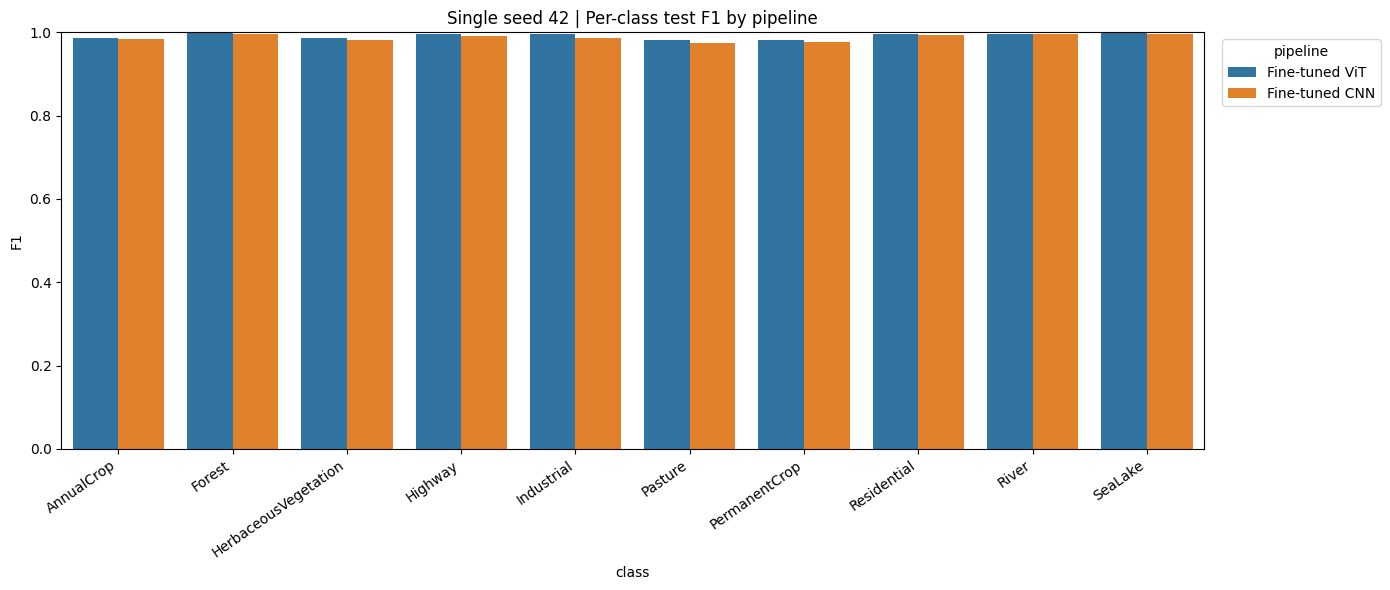

Key takeaway: the largest across-pipeline per-class F1 gap was 0.009 for Industrial in this test set.


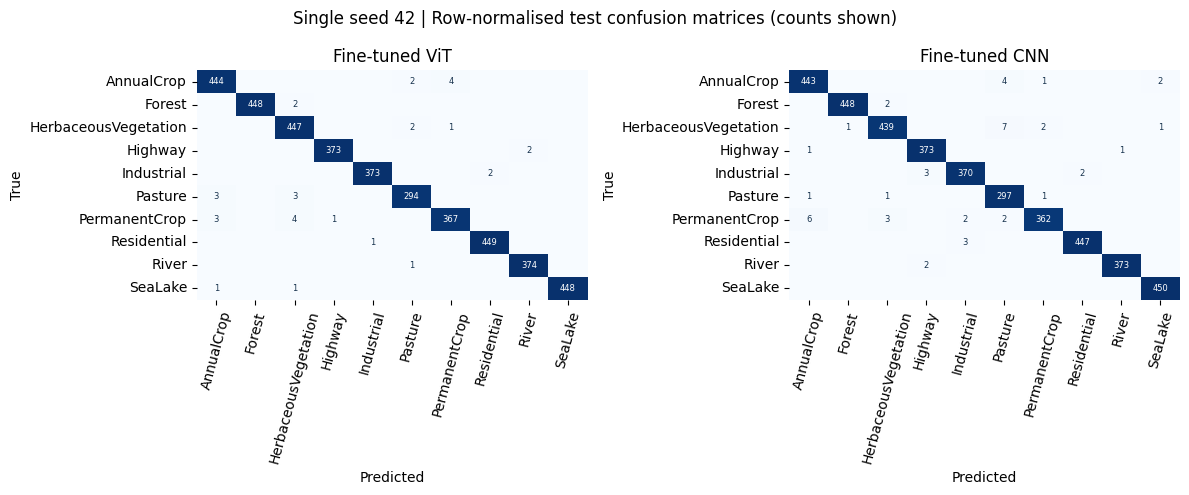

Key takeaway: in this experiment's test results, the diagonal is per-class recall and off-diagonal cells show which labels these pipelines confused.
Fine-tuned ViT: top 3 unordered pairs account for 51.5% of 33 errors.
Fine-tuned CNN: top 3 unordered pairs account for 41.7% of 48 errors.


### Single-seed experiment — top unordered confusion pairs

,pipeline,unordered pair,errors,share of all errors
0,Fine-tuned ViT,AnnualCrop ↔ PermanentCrop,7,0.212121
1,Fine-tuned ViT,AnnualCrop ↔ Pasture,5,0.151515
2,Fine-tuned ViT,HerbaceousVegetation ↔ Pasture,5,0.151515
3,Fine-tuned ViT,HerbaceousVegetation ↔ PermanentCrop,5,0.151515
4,Fine-tuned ViT,Industrial ↔ Residential,3,0.090909
5,Fine-tuned CNN,HerbaceousVegetation ↔ Pasture,8,0.166667
6,Fine-tuned CNN,AnnualCrop ↔ PermanentCrop,7,0.145833
7,Fine-tuned CNN,AnnualCrop ↔ Pasture,5,0.104167
8,Fine-tuned CNN,HerbaceousVegetation ↔ PermanentCrop,5,0.104167
9,Fine-tuned CNN,Industrial ↔ Residential,5,0.104167


In this experiment, H2 is not supported: top 3 unordered pairs must account for at least 50% of every evaluated model's errors.
H1 evidence about these two specific fine-tuned pipelines on this test set: ViT accuracy=0.9919; CNN accuracy=0.9881; b (ViT right/CNN wrong)=31; c (CNN right/ViT wrong)=16; exact two-sided p=0.0399861; alpha=0.05. Verdict: supported for ViT.


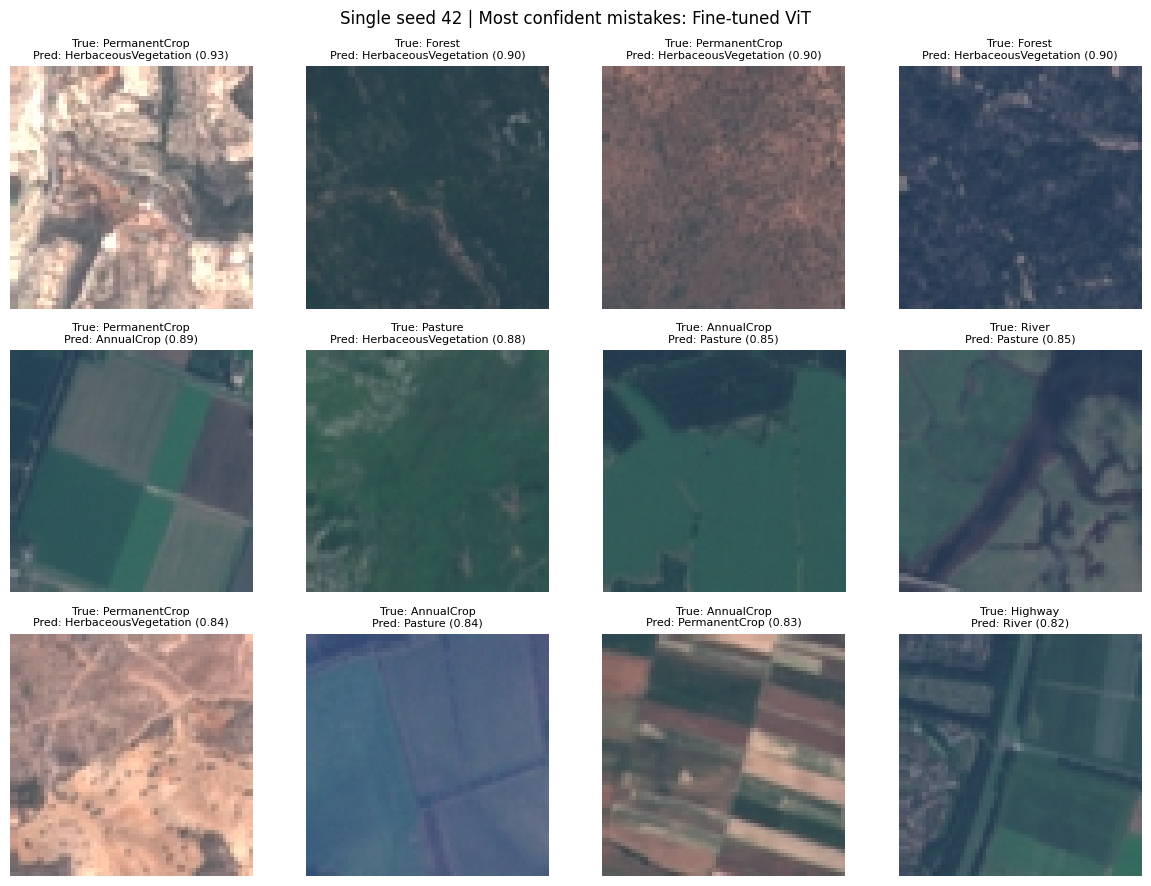

Key takeaway: the validation-selected Fine-tuned ViT pipeline made 33 test mistakes; the grid shows up to 12 highest-confidence cases.


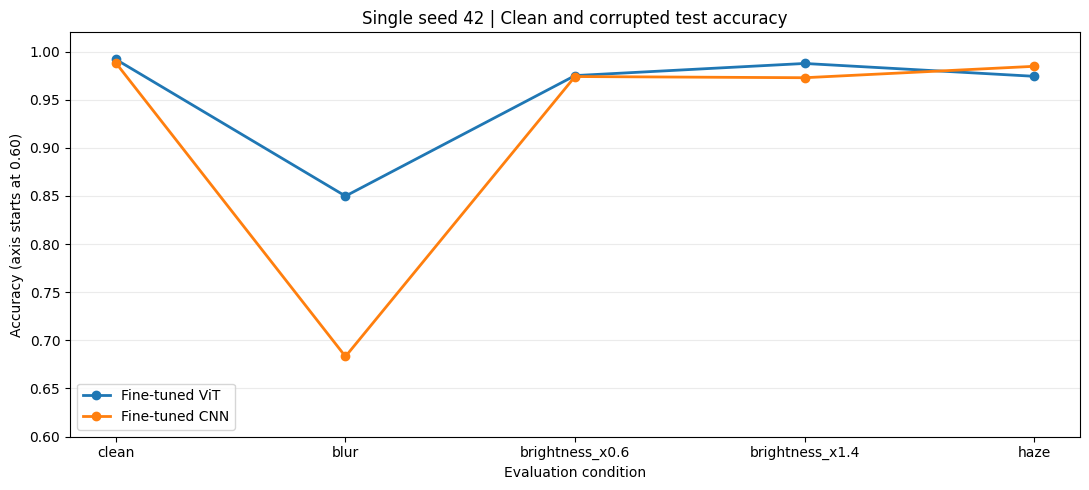

Key takeaway: in this experiment, the largest difference in ViT-versus-CNN accuracy drop was 16.30 percentage points for blur.
In this experiment, H3 is supported: at least one absolute drop difference must exceed 1.0 percentage point.


### Single-seed experiment — corruption accuracy drops

,pipeline,condition,clean accuracy,corrupted accuracy,drop (percentage points)
0,Fine-tuned ViT,blur,0.991852,0.849877,14.197531
1,Fine-tuned ViT,brightness_x0.6,0.991852,0.975062,1.679012
2,Fine-tuned ViT,brightness_x1.4,0.991852,0.987654,0.419753
3,Fine-tuned ViT,haze,0.991852,0.974321,1.753086
4,Fine-tuned CNN,blur,0.988148,0.683210,30.493827
5,Fine-tuned CNN,brightness_x0.6,0.988148,0.974074,1.407407
6,Fine-tuned CNN,brightness_x1.4,0.988148,0.972840,1.530864
7,Fine-tuned CNN,haze,0.988148,0.984691,0.345679


No exact image-hash duplicates were found between train and test; no duplicate-excluded accuracy is needed.


In [ ]:
# Report single-seed evaluation and test-set bootstrap scope.
print(f"All model results in this notebook use a single training seed ({CONFIG['seed']}); test-set bootstrap intervals measure resampling variation only.")
# Select the best fine-tuned pipeline using validation macro-F1, before opening the test results.
best_model_key = max(("E1", "E2"), key=lambda key: results[key]["validation_macro_f1"])
best_model_result = results[best_model_key]
print(f"Validation-selected fine-tuned model for later error inspection and selective prediction: {MODEL_DISPLAY_NAMES[best_model_key]} ({best_model_result['model_name']}).")

# Freeze every selective-prediction threshold from validation before evaluating any clean test predictions.
threshold_model = create_timm_model(best_model_result["model_name"]).to(device)
threshold_model.load_state_dict(torch.load(CHECKPOINT_DIR / best_model_key / "best.pt", map_location=device))
validation_probabilities, validation_labels = evaluate_model(threshold_model, best_model_key, active_splits["validation"])
validation_confidence = validation_probabilities.max(axis=1)
validation_predictions = validation_probabilities.argmax(axis=1)
threshold_rows = []
frozen_thresholds = {}
for target_coverage in CONFIG["selective_coverages"]:
    sorted_confidence = np.sort(validation_confidence)
    cutoff_index = max(0, min(len(sorted_confidence) - 1, int(math.floor((1 - target_coverage) * len(sorted_confidence)))))
    threshold = float(sorted_confidence[cutoff_index])
    accepted = validation_confidence >= threshold
    accepted_accuracy = float(accuracy_score(validation_labels[accepted], validation_predictions[accepted])) if np.any(accepted) else None
    frozen_thresholds[f"coverage_{target_coverage:.2f}"] = threshold
    threshold_rows.append({"target coverage": target_coverage, "threshold (validation)": threshold, "validation accepted": int(accepted.sum()), "validation coverage": float(accepted.mean()) if len(accepted) else 0.0, "validation accepted accuracy": accepted_accuracy})

# Find the lowest validation threshold meeting the fixed target accuracy, or record that none is feasible.
recommended_threshold = None
for threshold in np.sort(np.unique(validation_confidence)):
    accepted = validation_confidence >= threshold
    if np.any(accepted) and accuracy_score(validation_labels[accepted], validation_predictions[accepted]) >= CONFIG["target_accuracy"]:
        recommended_threshold = float(threshold)
        break
if recommended_threshold is None:
    print(f"No feasible threshold found at target {CONFIG['target_accuracy']:.3f}; no recommended-threshold test application will be made.")
else:
    frozen_thresholds["recommended"] = recommended_threshold
    recommended_validation = validation_confidence >= recommended_threshold
    recommended_validation_accuracy = float(accuracy_score(validation_labels[recommended_validation], validation_predictions[recommended_validation]))
    print(f"Recommended threshold {recommended_threshold:.4f} meets validation accepted accuracy {recommended_validation_accuracy:.4f} at coverage {recommended_validation.mean():.3f}.")
del threshold_model, validation_probabilities
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Measure batch-one inference latency on synthetic input after warm-up; no test labels influence this measurement.
def measure_latency(model):
    model.eval()
    synthetic = torch.zeros(1, 3, CONFIG["image_size"], CONFIG["image_size"], device=device)
    with torch.inference_mode():
        for _ in range(CONFIG["latency_warmup_steps"]):
            with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                _ = model(synthetic)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        timings = []
        for _ in range(CONFIG["latency_measure_steps"]):
            started = time.perf_counter()
            with torch.amp.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                _ = model(synthetic)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            timings.append(time.perf_counter() - started)
    del synthetic
    return float(np.median(timings) * 1000)

# Load each validation-selected checkpoint and run its clean test predictions once for final reporting.
test_outputs = {}
latencies_ms = {}
for key in ("E1", "E2"):
    model = create_timm_model(results[key]["model_name"]).to(device)
    model.load_state_dict(torch.load(CHECKPOINT_DIR / key / "best.pt", map_location=device))
    latencies_ms[key] = measure_latency(model)
    test_probabilities, test_labels = evaluate_model(model, key, active_splits["test"])
    test_outputs[key] = {"probabilities": test_probabilities, "labels": test_labels, "predictions": test_probabilities.argmax(axis=1)}
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Generate paired ordinary test-index bootstrap samples and reuse the same indices for every model.
test_count = len(active_splits["test"])
bootstrap_rng = np.random.default_rng(CONFIG["bootstrap_seed"])
bootstrap_indices = bootstrap_rng.integers(0, test_count, size=(CONFIG["bootstrap_resamples"], test_count))
metric_rows = []
bootstrap_cache = {}
for key in ("E1", "E2"):
    labels = test_outputs[key]["labels"]
    predictions = test_outputs[key]["predictions"]
    accuracy_samples = np.empty(CONFIG["bootstrap_resamples"])
    f1_samples = np.empty(CONFIG["bootstrap_resamples"])
    for sample_number, sample_indices in enumerate(bootstrap_indices):
        sampled_labels = labels[sample_indices]
        sampled_predictions = predictions[sample_indices]
        accuracy_samples[sample_number] = accuracy_score(sampled_labels, sampled_predictions)
        f1_samples[sample_number] = f1_score(sampled_labels, sampled_predictions, labels=np.arange(len(class_names)), average="macro", zero_division=0)
    bootstrap_cache[key] = {"accuracy": accuracy_samples, "macro_f1": f1_samples}
    low, high = np.percentile(accuracy_samples, CONFIG["bootstrap_percentiles"])
    f1_low, f1_high = np.percentile(f1_samples, CONFIG["bootstrap_percentiles"])
    metric_rows.append({"pipeline": MODEL_DISPLAY_NAMES[key] + " (single seed)", "accuracy": accuracy_score(labels, predictions), "accuracy 95% test-set bootstrap CI": f"[{low:.4f}, {high:.4f}]", "macro-F1": f1_score(labels, predictions, average="macro", zero_division=0), "macro-F1 95% test-set bootstrap CI": f"[{f1_low:.4f}, {f1_high:.4f}]", "macro precision": precision_score(labels, predictions, average="macro", zero_division=0), "macro recall": recall_score(labels, predictions, average="macro", zero_division=0), "parameters": results[key]["parameter_count"], "checkpoint MB": results[key]["checkpoint_mb"], "batch-1 latency ms": latencies_ms.get(key, np.nan), "GPU": gpu_name})

# Add the paired accuracy-difference interval as an informational measure, separate from H1's McNemar rule.
paired_difference = bootstrap_cache["E1"]["accuracy"] - bootstrap_cache["E2"]["accuracy"]
paired_difference_ci = np.percentile(paired_difference, CONFIG["bootstrap_percentiles"])
metric_table = pd.DataFrame(metric_rows)
display(Markdown(f"### {TABLE_BANNER} — master results (single seed)"))
display(metric_table)
print("Test-set bootstrap intervals: variation from resampling the test set only, NOT from different training seeds.")
print(f"Paired test accuracy difference (ViT − CNN), informational 95% percentile interval: [{paired_difference_ci[0]:.4f}, {paired_difference_ci[1]:.4f}].")
metric_table.to_csv(OUTPUT_DIR / "results_table.csv", index=False)

# Add computed clean-test metrics to the persistent result record.
for key in test_outputs:
    labels = test_outputs[key]["labels"]
    predictions = test_outputs[key]["predictions"]
    results[key]["test_accuracy"] = float(accuracy_score(labels, predictions))
    results[key]["test_macro_f1"] = float(f1_score(labels, predictions, average="macro", zero_division=0))
    results[key]["test_macro_precision"] = float(precision_score(labels, predictions, average="macro", zero_division=0))
    results[key]["test_macro_recall"] = float(recall_score(labels, predictions, average="macro", zero_division=0))
    if key in bootstrap_cache:
        results[key]["accuracy_ci"] = np.percentile(bootstrap_cache[key]["accuracy"], CONFIG["bootstrap_percentiles"]).tolist()
        results[key]["macro_f1_ci"] = np.percentile(bootstrap_cache[key]["macro_f1"], CONFIG["bootstrap_percentiles"]).tolist()
results["paired_accuracy_difference_ci"] = paired_difference_ci.tolist()
save_results()

# Build per-class precision, recall and F1 values from the same probability-derived test predictions.
class_metric_rows = []
for key in test_outputs:
    report = classification_report(test_outputs[key]["labels"], test_outputs[key]["predictions"], labels=np.arange(len(class_names)), target_names=class_names, output_dict=True, zero_division=0)
    for class_name in class_names:
        class_metric_rows.append({"model_key": key, "pipeline": MODEL_DISPLAY_NAMES[key], "class": class_name, "precision": report[class_name]["precision"], "recall": report[class_name]["recall"], "F1": report[class_name]["f1-score"]})
class_metric_table = pd.DataFrame(class_metric_rows)
display(Markdown(f"### {TABLE_BANNER} — per-class precision, recall and F1"))
display(class_metric_table.drop(columns=["model_key"]))
class_metric_table.drop(columns=["model_key"]).to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)

# Plot class-wise F1 and automatically describe the largest observed model gap.
fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=class_metric_table, x="class", y="F1", hue="pipeline", hue_order=[MODEL_DISPLAY_NAMES[key] for key in test_outputs], ax=ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1.01, 1))
ax.set_ylim(0, 1)
ax.set_title(figure_title("Per-class test F1 by pipeline"))
plt.xticks(rotation=35, ha="right")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "per_class_f1.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
class_f1_gaps = class_metric_table.groupby("class")["F1"].agg(lambda values: float(values.max() - values.min()))
print(f"Key takeaway: the largest across-pipeline per-class F1 gap was {class_f1_gaps.max():.3f} for {class_f1_gaps.idxmax()} in this test set.")

# Compute row-normalised confusion matrices and unordered class-pair counts for each evaluated pipeline.
pair_counts_by_model = {}
fig, axes = plt.subplots(1, len(test_outputs), figsize=(6 * len(test_outputs), 5))
if len(test_outputs) == 1:
    axes = [axes]
for axis, key in zip(axes, test_outputs):
    labels = test_outputs[key]["labels"]
    predictions = test_outputs[key]["predictions"]
    count_matrix = confusion_matrix(labels, predictions, labels=np.arange(len(class_names)))
    row_totals = np.maximum(count_matrix.sum(axis=1, keepdims=True), 1)
    matrix = count_matrix / row_totals
    count_annotations = np.where(count_matrix > 0, count_matrix.astype(str), "")
    sns.heatmap(matrix, ax=axis, cmap="Blues", vmin=0, vmax=1, annot=count_annotations, fmt="", annot_kws={"fontsize": 6}, xticklabels=class_names, yticklabels=class_names, cbar=False)
    for annotation, value in zip(axis.texts, matrix.ravel()):
        annotation.set_color("white" if value >= 0.50 else "#17324D")
    axis.set_title(MODEL_DISPLAY_NAMES[key])
    axis.set_xlabel("Predicted")
    axis.set_ylabel("True")
    axis.tick_params(axis="x", rotation=75)
    axis.tick_params(axis="y", rotation=0)
    unordered_counts = defaultdict(int)
    for true_label, predicted_label in zip(labels, predictions):
        if true_label != predicted_label:
            unordered_counts[tuple(sorted((int(true_label), int(predicted_label))))] += 1
    pair_counts_by_model[key] = unordered_counts
fig.suptitle(figure_title("Row-normalised test confusion matrices (counts shown)"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "confusion_matrices.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print("Key takeaway: in this experiment's test results, the diagonal is per-class recall and off-diagonal cells show which labels these pipelines confused.")

# Report top-five unordered confusions and calculate H2 using the top three pairs' share of all errors.
h2_shares = {}
top_pair_rows = []
for key, pair_counts in pair_counts_by_model.items():
    total_errors = int(np.sum(test_outputs[key]["predictions"] != test_outputs[key]["labels"]))
    if total_errors == 0:
        print(f"{MODEL_DISPLAY_NAMES[key]}: zero test errors; excluded from H2 and noted.")
        h2_shares[key] = None
        continue
    top_pairs = sorted(pair_counts.items(), key=lambda item: (-item[1], item[0]))
    top_three_count = sum(count for _, count in top_pairs[:CONFIG["h2_top_pairs"]])
    share = top_three_count / total_errors
    h2_shares[key] = share
    for pair, count in top_pairs[:5]:
        top_pair_rows.append({"pipeline": MODEL_DISPLAY_NAMES[key], "unordered pair": f"{class_names[pair[0]]} ↔ {class_names[pair[1]]}", "errors": count, "share of all errors": count / total_errors})
    print(f"{MODEL_DISPLAY_NAMES[key]}: top {CONFIG['h2_top_pairs']} unordered pairs account for {share:.1%} of {total_errors} errors.")
h2_included = [value for value in h2_shares.values() if value is not None]
h2_supported = bool(h2_included) and all(value >= CONFIG["h2_share_threshold"] for value in h2_included)
h2_verdict = "supported" if h2_supported else "not supported"
show_pairs = pd.DataFrame(top_pair_rows)
display(Markdown(f"### {TABLE_BANNER} — top unordered confusion pairs"))
display(show_pairs)
print(f"In this experiment, H2 is {h2_verdict}: top {CONFIG['h2_top_pairs']} unordered pairs must account for at least {CONFIG['h2_share_threshold']:.0%} of every evaluated model's errors.")

# Compute the exact two-sided McNemar binomial test from paired test predictions.
vit_labels = test_outputs["E1"]["labels"]
vit_predictions = test_outputs["E1"]["predictions"]
cnn_predictions = test_outputs["E2"]["predictions"]
b = int(np.sum((vit_predictions == vit_labels) & (cnn_predictions != vit_labels)))
c = int(np.sum((cnn_predictions == vit_labels) & (vit_predictions != vit_labels)))
mcnemar_p = float(binomtest(min(b, c), b + c, p=0.5, alternative="two-sided").pvalue) if b + c else 1.0
vit_accuracy = float(accuracy_score(vit_labels, vit_predictions))
cnn_accuracy = float(accuracy_score(vit_labels, cnn_predictions))
if vit_accuracy > cnn_accuracy and mcnemar_p < CONFIG["hypothesis_alpha"]:
    h1_verdict = "supported for ViT"
elif cnn_accuracy > vit_accuracy and mcnemar_p < CONFIG["hypothesis_alpha"]:
    h1_verdict = "not supported; evidence favours CNN on this test set"
else:
    h1_verdict = "inconclusive"
print(f"H1 evidence about these two specific fine-tuned pipelines on this test set: ViT accuracy={vit_accuracy:.4f}; CNN accuracy={cnn_accuracy:.4f}; b (ViT right/CNN wrong)={b}; c (CNN right/ViT wrong)={c}; exact two-sided p={mcnemar_p:.6g}; alpha={CONFIG['hypothesis_alpha']}. Verdict: {h1_verdict}.")

# Identify the 12 highest-confidence mistakes from the validation-selected fine-tuned model.
best_test = test_outputs[best_model_key]
best_confidence = best_test["probabilities"].max(axis=1)
mistake_indices = np.flatnonzero(best_test["predictions"] != best_test["labels"])
top_mistakes = mistake_indices[np.argsort(best_confidence[mistake_indices])[::-1][:CONFIG["mistake_grid_count"]]]
if len(top_mistakes) == 0:
    print("The validation-selected model made no test mistakes; an explanatory placeholder figure is saved.")
    fig, axis = plt.subplots(figsize=CONFIG["figure_size"])
    axis.text(0.5, 0.5, "No test mistakes in this run", ha="center", va="center", fontsize=16)
    axis.axis("off")
    axis.set_title(figure_title(f"Most confident mistakes: {MODEL_DISPLAY_NAMES[best_model_key]}"))
    fig.savefig(FIGURE_DIR / "confident_mistakes.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    plt.show()
    print(f"Key takeaway: the validation-selected {MODEL_DISPLAY_NAMES[best_model_key]} pipeline made no test mistakes in this run.")
else:
    columns = 4
    rows = math.ceil(len(top_mistakes) / columns)
    fig, axes = plt.subplots(rows, columns, figsize=(12, 3 * rows))
    axes = np.asarray(axes).reshape(-1)
    for plot_index, local_index in enumerate(top_mistakes):
        image_index = active_splits["test"][local_index]
        axes[plot_index].imshow(images_u8[image_index].permute(1, 2, 0).numpy())
        true_name = class_names[int(best_test["labels"][local_index])]
        predicted_name = class_names[int(best_test["predictions"][local_index])]
        axes[plot_index].set_title(f"True: {true_name}\nPred: {predicted_name} ({best_confidence[local_index]:.2f})", fontsize=8)
        axes[plot_index].axis("off")
    for axis in axes[len(top_mistakes):]:
        axis.axis("off")
    fig.suptitle(figure_title(f"Most confident mistakes: {MODEL_DISPLAY_NAMES[best_model_key]}"))
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "confident_mistakes.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
    plt.show()
    print(f"Key takeaway: the validation-selected {MODEL_DISPLAY_NAMES[best_model_key]} pipeline made {len(mistake_indices)} test mistakes; the grid shows up to {len(top_mistakes)} highest-confidence cases.")

# Measure simple corruption accuracy for ViT and CNN, perturbing the 64×64 images before resize.
robustness = {key: {} for key in ("E1", "E2")}
robustness_predictions = {key: {} for key in ("E1", "E2")}
for key in ("E1", "E2"):
    model = create_timm_model(results[key]["model_name"]).to(device)
    model.load_state_dict(torch.load(CHECKPOINT_DIR / key / "best.pt", map_location=device))
    for corruption in CONFIG["corruptions"]:
        probabilities, labels = evaluate_model(model, key, active_splits["test"], corruption=corruption)
        accuracy = float(accuracy_score(labels, probabilities.argmax(axis=1)))
        robustness[key][corruption] = {"accuracy": accuracy, "drop_pp": (results[key]["test_accuracy"] - accuracy) * 100}
        robustness_predictions[key][corruption] = probabilities.argmax(axis=1)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
results["robustness"] = {key: {condition: value["drop_pp"] for condition, value in conditions.items()} for key, conditions in robustness.items()}
save_results()

# Plot clean and corrupted test accuracy, then compute H3 using the fixed one-percentage-point rule.
robust_rows = []
for key in ("E1", "E2"):
    robust_rows.append({"pipeline": MODEL_DISPLAY_NAMES[key], "condition": "clean", "accuracy": results[key]["test_accuracy"]})
    for condition in CONFIG["corruptions"]:
        robust_rows.append({"pipeline": MODEL_DISPLAY_NAMES[key], "condition": condition, "accuracy": robustness[key][condition]["accuracy"]})
robust_table = pd.DataFrame(robust_rows)
robust_table["condition"] = pd.Categorical(robust_table["condition"], categories=["clean"] + CONFIG["corruptions"], ordered=True)
fig, ax = plt.subplots(figsize=(11, 5))
for pipeline_name in [MODEL_DISPLAY_NAMES[key] for key in ("E1", "E2")]:
    subset = robust_table[robust_table["pipeline"] == pipeline_name].sort_values("condition")
    ax.plot(subset["condition"].astype(str), subset["accuracy"], marker="o", linewidth=2, label=pipeline_name)
y_axis_floor = 0.60 if robust_table["accuracy"].min() >= 0.60 else 0.0
ax.set_ylim(y_axis_floor, 1.02)
ax.set_title(figure_title("Clean and corrupted test accuracy"))
ax.set_ylabel(f"Accuracy (axis starts at {y_axis_floor:.2f})" if y_axis_floor else "Accuracy")
ax.set_xlabel("Evaluation condition")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "robustness_accuracy.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
drop_differences = {condition: abs(robustness["E1"][condition]["drop_pp"] - robustness["E2"][condition]["drop_pp"]) for condition in CONFIG["corruptions"]}
h3_supported = any(value > CONFIG["h3_drop_difference_pp"] for value in drop_differences.values())
h3_verdict = "supported" if h3_supported else "not supported"
largest_drop_difference = max(drop_differences, key=drop_differences.get)
print(f"Key takeaway: in this experiment, the largest difference in ViT-versus-CNN accuracy drop was {drop_differences[largest_drop_difference]:.2f} percentage points for {largest_drop_difference}.")
print(f"In this experiment, H3 is {h3_verdict}: at least one absolute drop difference must exceed {CONFIG['h3_drop_difference_pp']:.1f} percentage point.")
robust_drop_rows = [{"pipeline": MODEL_DISPLAY_NAMES[key], "condition": condition, "clean accuracy": results[key]["test_accuracy"], "corrupted accuracy": robustness[key][condition]["accuracy"], "drop (percentage points)": robustness[key][condition]["drop_pp"]} for key in ("E1", "E2") for condition in CONFIG["corruptions"]]
robust_drop_table = pd.DataFrame(robust_drop_rows)
display(Markdown(f"### {TABLE_BANNER} — corruption accuracy drops"))
display(robust_drop_table)

# Report test accuracy excluding exact-duplicate images that cross from training into the test set, if any exist.
train_hashes = set(image_hashes[index] for index in split_indices["train"])
test_duplicate_local = np.asarray([local for local, index in enumerate(active_splits["test"]) if image_hashes[index] in train_hashes], dtype=np.int64)
if len(test_duplicate_local):
    duplicate_local_set = set(test_duplicate_local.tolist())
    keep_local = np.asarray([local for local in range(len(active_splits["test"])) if local not in duplicate_local_set], dtype=np.int64)
    if len(keep_local):
        print(f"Found {len(test_duplicate_local)} test images with exact train duplicates. Accuracy excluding them: ViT={accuracy_score(vit_labels[keep_local], vit_predictions[keep_local]):.4f}; CNN={accuracy_score(vit_labels[keep_local], cnn_predictions[keep_local]):.4f}.")
    else:
        print(f"Found {len(test_duplicate_local)} test images with exact train duplicates; no test images remain after exclusion, so duplicate-excluded accuracy is undefined.")
else:
    print("No exact image-hash duplicates were found between train and test; no duplicate-excluded accuracy is needed.")

# Save all hypothesis verdicts and paired test counts for later export.
results["hypotheses"] = {"H1": {"verdict": h1_verdict, "b": b, "c": c, "p_value": mcnemar_p}, "H2": {"verdict": h2_verdict, "shares": h2_shares}, "H3": {"verdict": h3_verdict, "drop_differences_pp": drop_differences}}
save_results()


### How to read the per-class F1 figure

Each bar is a class-level test F1 for one evaluated pipeline. A low bar identifies a class where precision and recall jointly need inspection; it does not explain why the error occurred.

### How to read the confusion matrices

Rows are true classes and each row is normalised to sum to one, so the colour shows the fraction of each class predicted in each category. The diagonal is class recall. Each nonzero cell is annotated with its raw image count; the largest off-diagonal confusions are also listed as unordered pairs.

### How to read the confident-mistake grid

The grid shows up to 12 wrong predictions with the highest softmax confidence from the validation-selected fine-tuned pipeline. High-confidence mistakes are useful candidates for human review.

### How to read the robustness figure

The clean point is the reference. Each other point is accuracy after a simple corruption applied to the 64×64 image before resizing. The plot starts its y-axis at 0.60 when all measured accuracies are at least 0.60, and says so on the axis; otherwise it starts at zero. These are controlled stress tests, not a comprehensive measure of real satellite-image robustness.


## Section 6: Bias, ethics and societal considerations [Rubric: 20%]

**Concept box.** Good average accuracy does not guarantee equal performance across labels or safe use. We inspect class gaps, data limitations, risks and a confidence-based review option. Expect class-wise evidence and explicit limits. A common mistake is to treat a confidence score as a calibrated probability of correctness.

### 6.1 Dataset limitations checklist (Datasheets for Datasets [10])

- [x] **Coverage:** European scenes only; the dataset does not support a claim of worldwide performance.
- [x] **Time:** imagery represents a limited time snapshot, not current land cover.
- [x] **Ambiguous labels:** Residential versus Industrial and Pasture versus Herbaceous vegetation can be visually similar.
- [x] **Label noise:** scene labels may not describe every pixel or mixed patch equally well.
- [x] **Resolution:** 10 m per pixel; each 64×64 patch covers roughly 640 m × 640 m.
- [x] **Spectral information:** this experiment uses RGB and omits infrared bands available in Sentinel-2.
- [x] **Spatial leakage:** random splits can separate neighbouring patches across splits and inflate scores; results do NOT demonstrate generalisation to new geographic locations.
- [x] **Metadata:** EuroSAT has no country/region metadata suitable for directly measuring geographic fairness.

### 6.2 Potential-use risk table

| Use case | Potential benefit | Harm if wrong | Mitigation |
|---|---|---|---|
| Agricultural subsidy checks | Flag fields for faster review | Incorrectly deny support or misclassify crop type | Keep a human appeal process; use current parcel evidence |
| Land taxation | Help prioritise map updates | Incorrect tax category or unfair burden | Never use this model as the sole legal evidence |
| Urban planning | Rapid land-cover summaries | Miss informal settlements or mislabel green space | Validate locally and publish uncertainty and limits |
| Environmental monitoring | Identify candidate areas for inspection | Miss habitat or trigger false alarms | Confirm with field data and multispectral imagery |
| Disaster response | Rapidly triage damaged or flooded areas | Misallocate responders or resources | Human command review and independent sensor sources |
| Defence / surveillance dual use | Broad-area scene categorisation | Enable harmful targeting or intrusive surveillance | Avoid individual targeting; require governance, purpose limits and review |


### 6.3 Per-class corruption diagnostics and robustness findings [7]

The next cell reports clean accuracy minus corrupted accuracy, in percentage points, for each class under that pipeline’s worst-performing corruption. A positive value means accuracy fell; a negative value means accuracy improved. This is a class-wise stress-test diagnostic, not a demographic or geographic fairness measurement.

The next code cell’s model card computes the Forest and Residential accuracy drops under blur from the current run and reports the direction of the ViT–CNN comparison under blur and haze. Use those newly computed values in the report. These are measured stress tests, not claims about every real-world image shift.

The generated model card follows the model-card reporting approach [9]. Selective classification and abstention are informed by the selective-prediction literature [17].

Fine-tuned ViT: test per-class F1 gap=0.016; worst class=Pasture; largest overall drop condition=blur.
Fine-tuned CNN: test per-class F1 gap=0.023; worst class=Pasture; largest overall drop condition=blur.


### Single-seed experiment — per-class accuracy change under each pipeline's worst corruption

,pipeline,class,clean accuracy,accuracy change under worst corruption (pp; negative = gain)
0,Fine-tuned ViT,AnnualCrop,0.986667,-0.666667
1,Fine-tuned ViT,Forest,0.995556,50.888889
2,Fine-tuned ViT,HerbaceousVegetation,0.993333,1.555556
3,Fine-tuned ViT,Highway,0.994667,1.600000
4,Fine-tuned ViT,Industrial,0.994667,1.866667
5,Fine-tuned ViT,Pasture,0.980000,3.000000
6,Fine-tuned ViT,PermanentCrop,0.978667,30.666667
7,Fine-tuned ViT,Residential,0.997778,43.555556
8,Fine-tuned ViT,River,0.997333,2.933333
9,Fine-tuned ViT,SeaLake,0.995556,-0.444444


Most-confused test pairs by error count:


,pipeline,unordered pair,errors,share of all errors
5,Fine-tuned CNN,HerbaceousVegetation ↔ Pasture,8,0.166667
0,Fine-tuned ViT,AnnualCrop ↔ PermanentCrop,7,0.212121
6,Fine-tuned CNN,AnnualCrop ↔ PermanentCrop,7,0.145833


Target 100%: test accepted 4050, rejected 0, realised coverage 100.0%, accepted accuracy 0.9919; rejected per class {'AnnualCrop': 0, 'Forest': 0, 'HerbaceousVegetation': 0, 'Highway': 0, 'Industrial': 0, 'Pasture': 0, 'PermanentCrop': 0, 'Residential': 0, 'River': 0, 'SeaLake': 0}.
Target 90%: test accepted 3659, rejected 391, realised coverage 90.3%, accepted accuracy 0.9992; rejected per class {'AnnualCrop': 66, 'Forest': 15, 'HerbaceousVegetation': 71, 'Highway': 25, 'Industrial': 37, 'Pasture': 30, 'PermanentCrop': 52, 'Residential': 22, 'River': 46, 'SeaLake': 27}.
Target 80%: test accepted 3215, rejected 835, realised coverage 79.4%, accepted accuracy 0.9997; rejected per class {'AnnualCrop': 114, 'Forest': 51, 'HerbaceousVegetation': 138, 'Highway': 57, 'Industrial': 107, 'Pasture': 58, 'PermanentCrop': 101, 'Residential': 51, 'River': 97, 'SeaLake': 61}.
Target 70%: test accepted 2821, rejected 1229, realised coverage 69.7%, accepted accuracy 0.9996; rejected per class {'Annua

### Single-seed experiment — validation-selected selective prediction thresholds

,target coverage,threshold (validation),validation accepted,validation coverage,validation accepted accuracy,test threshold,test accepted,test rejected,test coverage,test accepted accuracy
0,1.0,0.385397,4050,1.000000,0.990123,0.385397,4050,0,1.000000,0.991852
1,0.9,0.899978,3646,0.900247,0.998080,0.899978,3659,391,0.903457,0.999180
2,0.8,0.904851,3241,0.800247,0.998766,0.904851,3215,835,0.793827,0.999689
3,0.7,0.907253,2835,0.700000,0.999295,0.907253,2821,1229,0.696543,0.999646
4,0.5,0.910273,2025,0.500000,0.999012,0.910273,1987,2063,0.490617,0.999497
5,recommended,0.831854,3975,0.981481,0.995220,0.831854,3982,68,0.983210,0.997489


Realised test coverage can differ from target coverage because the test confidence distribution and tied scores can differ. Rejected patches should receive human review.


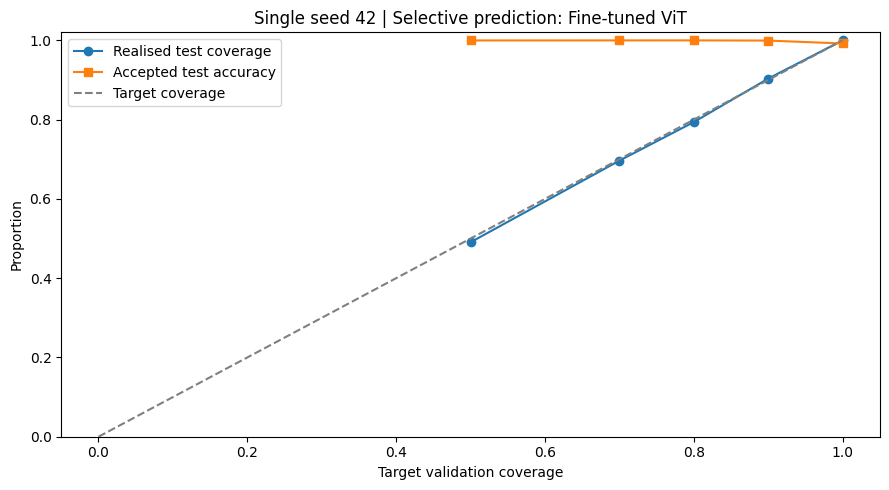

Key takeaway: in this experiment, the plot compares target validation coverage with realised test coverage and accepted-sample accuracy; it does not certify calibration.
MODEL CARD — vit_base_patch16_224.augreg_in21k_ft_in1k (single seed 42)

Task: classify 64×64 EuroSAT RGB patches into 10 land-cover labels after resizing to 224×224.
Selection: best validation macro-F1 among the fine-tuned ViT and CNN pipelines.
Test accuracy: 0.9919; test macro-F1: 0.9916.
Worst test class by F1: Pasture (F1 0.9816).
Blur class drops (ViT/CNN): Forest 50.9/99.3 pp; Residential 43.6/93.1 pp. Corruption robustness: ViT loses less accuracy under blur; CNN loses less accuracy under haze.
Reporting follows the model-card approach [9].
Training data: Europe-only EuroSAT random split; neighbouring patches may cross splits.
Known limits: one training seed, RGB-only inputs, possible label ambiguity, no country metadata, and no demonstrated geographic generalisation.
Pretraining risk: the selected pipeline inh

In [ ]:
# Measure per-class F1 gaps, the worst fine-tuned class, and class accuracy change under the worst corruption.
fairness_rows = []
for key in ("E1", "E2"):
    rows = class_metric_table[class_metric_table["model_key"] == key].set_index("class")
    worst_class = rows["F1"].idxmin()
    per_class_accuracy = {}
    labels = test_outputs[key]["labels"]
    predictions = test_outputs[key]["predictions"]
    for class_id, class_name in enumerate(class_names):
        mask = labels == class_id
        per_class_accuracy[class_name] = float(np.mean(predictions[mask] == labels[mask])) if np.any(mask) else float("nan")
    worst_condition = max(CONFIG["corruptions"], key=lambda condition: robustness[key][condition]["drop_pp"])
    corrupted_predictions = robustness_predictions[key][worst_condition]
    for class_id, class_name in enumerate(class_names):
        mask = labels == class_id
        corrupted_accuracy = float(np.mean(corrupted_predictions[mask] == labels[mask])) if np.any(mask) else float("nan")
        fairness_rows.append({"pipeline": MODEL_DISPLAY_NAMES[key], "class": class_name, "clean accuracy": per_class_accuracy[class_name], "accuracy change under worst corruption (pp; negative = gain)": (per_class_accuracy[class_name] - corrupted_accuracy) * 100})
    print(f"{MODEL_DISPLAY_NAMES[key]}: test per-class F1 gap={rows['F1'].max() - rows['F1'].min():.3f}; worst class={worst_class}; largest overall drop condition={worst_condition}.")
fairness_table = pd.DataFrame(fairness_rows)
display(Markdown(f"### {TABLE_BANNER} — per-class accuracy change under each pipeline's worst corruption"))
display(fairness_table)
if len(show_pairs):
    most_confused = show_pairs.sort_values("errors", ascending=False).head(3)
    print("Most-confused test pairs by error count:")
    display(most_confused)

# Apply the thresholds frozen before test evaluation to the stored clean test probabilities.
best_test_confidence = test_outputs[best_model_key]["probabilities"].max(axis=1)
best_test_predictions = test_outputs[best_model_key]["predictions"]
best_test_labels = test_outputs[best_model_key]["labels"]
for row, target_coverage in zip(threshold_rows, CONFIG["selective_coverages"]):
    threshold = frozen_thresholds[f"coverage_{target_coverage:.2f}"]
    accepted = best_test_confidence >= threshold
    rejected_by_class = {class_name: int(np.sum((best_test_labels == index) & ~accepted)) for index, class_name in enumerate(class_names)}
    row.update({"test threshold": threshold, "test accepted": int(accepted.sum()), "test rejected": int((~accepted).sum()), "test coverage": float(accepted.mean()) if len(accepted) else 0.0, "test accepted accuracy": float(accuracy_score(best_test_labels[accepted], best_test_predictions[accepted])) if np.any(accepted) else "no samples accepted", "rejected per class": rejected_by_class})
    if not np.any(accepted):
        print(f"Target {target_coverage:.0%}: no samples accepted on test; accepted 0, rejected {len(accepted)}, rejected per class {rejected_by_class}.")
    else:
        print(f"Target {target_coverage:.0%}: test accepted {int(accepted.sum())}, rejected {int((~accepted).sum())}, realised coverage {accepted.mean():.1%}, accepted accuracy {accuracy_score(best_test_labels[accepted], best_test_predictions[accepted]):.4f}; rejected per class {rejected_by_class}.")
if recommended_threshold is not None:
    accepted = best_test_confidence >= recommended_threshold
    rejected_by_class = {name: int(np.sum((best_test_labels == idx) & ~accepted)) for idx, name in enumerate(class_names)}
    recommended_test_accuracy = float(accuracy_score(best_test_labels[accepted], best_test_predictions[accepted])) if np.any(accepted) else "no samples accepted"
    print(f"Recommended cutoff test result: accepted {int(accepted.sum())}, rejected {int((~accepted).sum())}, realised coverage {accepted.mean():.1%}, accepted accuracy {recommended_test_accuracy}; rejected count by class: {rejected_by_class}.")
    threshold_rows.append({"target coverage": "recommended", "threshold (validation)": recommended_threshold, "validation accepted": int(recommended_validation.sum()), "validation coverage": float(recommended_validation.mean()), "validation accepted accuracy": recommended_validation_accuracy, "test threshold": recommended_threshold, "test accepted": int(accepted.sum()), "test rejected": int((~accepted).sum()), "test coverage": float(accepted.mean()), "test accepted accuracy": recommended_test_accuracy, "rejected per class": rejected_by_class})
selective_table = pd.DataFrame(threshold_rows)
display(Markdown(f"### {TABLE_BANNER} — validation-selected selective prediction thresholds"))
display(selective_table.drop(columns=["rejected per class"]))
selective_table.to_csv(OUTPUT_DIR / "selective_prediction.csv", index=False)
print("Realised test coverage can differ from target coverage because the test confidence distribution and tied scores can differ. Rejected patches should receive human review.")

# Plot realised test coverage and accepted accuracy at the frozen target-coverage thresholds.
fig, ax = plt.subplots(figsize=(9, 5))
plot_threshold_rows = [row for row in threshold_rows if isinstance(row["target coverage"], (float, int))]
ax.plot([row["target coverage"] for row in plot_threshold_rows], [row["test coverage"] for row in plot_threshold_rows], marker="o", label="Realised test coverage")
ax.plot([row["target coverage"] for row in plot_threshold_rows], [row["test accepted accuracy"] if isinstance(row["test accepted accuracy"], float) else np.nan for row in plot_threshold_rows], marker="s", label="Accepted test accuracy")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Target coverage")
ax.set_xlabel("Target validation coverage")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1.02)
ax.legend()
ax.set_title(figure_title(f"Selective prediction: {MODEL_DISPLAY_NAMES[best_model_key]}"))
fig.tight_layout()
fig.savefig(FIGURE_DIR / "selective_prediction.png", dpi=CONFIG["figure_dpi"], bbox_inches="tight")
plt.show()
print("Key takeaway: in this experiment, the plot compares target validation coverage with realised test coverage and accepted-sample accuracy; it does not certify calibration.")
# Build a short model card using measured metrics and explicit intended-use boundaries.
best_card = results[best_model_key]
worst_f1_row = class_metric_table[class_metric_table["model_key"] == best_model_key].sort_values("F1").iloc[0]

def class_accuracy_drop_pp(model_key, class_name, corruption):
    class_id = class_names.index(class_name)
    labels = test_outputs[model_key]["labels"]
    class_mask = labels == class_id
    if not np.any(class_mask):
        return float("nan")
    clean_predictions = test_outputs[model_key]["predictions"]
    changed_predictions = robustness_predictions[model_key][corruption]
    clean_accuracy = float(np.mean(clean_predictions[class_mask] == labels[class_mask]))
    changed_accuracy = float(np.mean(changed_predictions[class_mask] == labels[class_mask]))
    return (clean_accuracy - changed_accuracy) * 100

blur_class_drops = {
    class_name: {key: class_accuracy_drop_pp(key, class_name, "blur") for key in ("E1", "E2")}
    for class_name in ("Forest", "Residential")
}
blur_vit_drop = robustness["E1"]["blur"]["drop_pp"]
blur_cnn_drop = robustness["E2"]["blur"]["drop_pp"]
haze_vit_drop = robustness["E1"]["haze"]["drop_pp"]
haze_cnn_drop = robustness["E2"]["haze"]["drop_pp"]
blur_direction = "ViT loses less accuracy under blur" if blur_vit_drop < blur_cnn_drop else "CNN loses less accuracy under blur" if blur_cnn_drop < blur_vit_drop else "the models have equal blur drops"
haze_direction = "ViT loses less accuracy under haze" if haze_vit_drop < haze_cnn_drop else "CNN loses less accuracy under haze" if haze_cnn_drop < haze_vit_drop else "the models have equal haze drops"

model_card = "\n".join([
    f"MODEL CARD — {best_card['model_name']} (single seed {CONFIG['seed']})",
    "",
    "Task: classify 64×64 EuroSAT RGB patches into 10 land-cover labels after resizing to 224×224.",
    "Selection: best validation macro-F1 among the fine-tuned ViT and CNN pipelines.",
    f"Test accuracy: {best_card['test_accuracy']:.4f}; test macro-F1: {best_card['test_macro_f1']:.4f}.",
    f"Worst test class by F1: {worst_f1_row['class']} (F1 {worst_f1_row['F1']:.4f}).",
    f"Blur class drops (ViT/CNN): Forest {blur_class_drops['Forest']['E1']:.1f}/{blur_class_drops['Forest']['E2']:.1f} pp; Residential {blur_class_drops['Residential']['E1']:.1f}/{blur_class_drops['Residential']['E2']:.1f} pp. Corruption robustness: {blur_direction}; {haze_direction}.",
    "Reporting follows the model-card approach [9].",
    "Training data: Europe-only EuroSAT random split; neighbouring patches may cross splits.",
    "Known limits: one training seed, RGB-only inputs, possible label ambiguity, no country metadata, and no demonstrated geographic generalisation.",
    "Pretraining risk: the selected pipeline inherits biases and label-coverage limits from its ImageNet-pretrained weights.",
    "Use: educational comparison and candidate-map triage only; not an autonomous decision system. Require local validation and human review.",
])
print(model_card)

# Report fairness limitations in plain language, including the absence of geographic metadata.
print("EuroSAT has no country/region metadata for a direct geographic-fairness breakdown. Per-class F1 and corruption drops are useful diagnostics, not substitutes for evaluation on geographically held-out data.")


### How to read the selective-prediction figure

Confidence is the maximum softmax score for the validation-selected fine-tuned model. Thresholds are chosen on validation and frozen before applying them to test. Label smoothing does not impose a hard confidence cap. If this run’s validation confidence scores cluster tightly, its cutoffs will also be close together and the realised coverage steps may be coarse. Use the thresholds printed for this run; the 100% coverage and recommended target-accuracy cutoffs follow separate rules. Confidence is not guaranteed to be calibrated. Send rejected patches to a person for review [17].


## Section 7: Conclusion

**Concept box.** This section assembles the hypothesis verdicts for decision rules defined in CONFIG and the main limitations. Expect cautious statements tied to this test set. A common mistake is to turn one seed into a claim about all transformers or CNNs.


In [ ]:
# Print each hypothesis result and its rule using evidence-limited wording.
print(f"In this experiment, H1 is {h1_verdict}: ViT accuracy={vit_accuracy:.4f}, CNN accuracy={cnn_accuracy:.4f}, b={b}, c={c}, exact McNemar p={mcnemar_p:.6g}; rule: accuracy direction plus p < {CONFIG['hypothesis_alpha']}.")
print(f"In this experiment, H2 is {h2_verdict}: top-three unordered confusion-pair shares={h2_shares}; rule: at least {CONFIG['h2_share_threshold']:.0%} for both evaluated models.")
print(f"In this experiment, H3 is {h3_verdict}: ViT–CNN corruption-drop differences={drop_differences}; rule: any absolute difference > {CONFIG['h3_drop_difference_pp']:.1f} percentage point.")

# Non-binding sanity ranges are prompts to investigate, not targets to optimize toward.
sanity_ranges = {"ViT": (0.98, 0.995), "CNN": (0.975, 0.995)}
sanity_values = {"ViT": results["E1"]["test_accuracy"], "CNN": results["E2"]["test_accuracy"]}
for name, value in sanity_values.items():
    low, high = sanity_ranges[name]
    label = "inside typical range" if low <= value <= high else "outside typical range - investigate"
    print(f"Sanity report: {name} test accuracy {value:.4f} is {label} [{low:.3f}, {high:.3f}]. This is non-binding and does not change the experiment.")

print("Interpretation: these results describe these specific fine-tuned pipelines, recipe and test set. They do not establish inherent model-family superiority or generalisation to new geographic locations.")
print("Limitations: one training seed; confounded architecture, parameter count and pretraining recipes; BiT's documented 448 default versus 224 used; possible random-split spatial leakage; Europe-only coverage; RGB-only inputs.")
print("Future work: repeat across multiple training seeds, use 13-band multispectral inputs, test geographically held-out splits, add explainability maps and examine calibration. The current single-seed findings remain the primary reported experiment.")
print_computed_abstract()


In this experiment, H1 is supported for ViT: ViT accuracy=0.9919, CNN accuracy=0.9881, b=31, c=16, exact McNemar p=0.0399861; rule: accuracy direction plus p < 0.05.
In this experiment, H2 is not supported: top-three unordered confusion-pair shares={'E1': 0.5151515151515151, 'E2': 0.4166666666666667}; rule: at least 50% for both evaluated models.
In this experiment, H3 is supported: ViT–CNN corruption-drop differences={'blur': 16.296296296296287, 'brightness_x0.6': 0.2716049382716079, 'brightness_x1.4': 1.111111111111096, 'haze': 1.4074074074074128}; rule: any absolute difference > 1.0 percentage point.
Sanity report: ViT test accuracy 0.9919 is inside typical range [0.980, 0.995]. This is non-binding and does not change the experiment.
Sanity report: CNN test accuracy 0.9881 is inside typical range [0.975, 0.995]. This is non-binding and does not change the experiment.
Interpretation: these results describe these specific fine-tuned pipelines, recipe and test set. They do not establis

## Section 8: Export and report helper

**Concept box.** The export cell writes a ZIP archive beside the configured outputs folder. The saved run log records that the archive was created in the Colab Drive location. The ZIP contains the report CSV, JSON and Markdown files plus figures; resumable checkpoints are kept separately.

In [ ]:
# Save a concise report-number file and a markdown table from the measured run.
report_lines = [
    "# EuroSAT report numbers",
    "",
    f"Run mode: {RUN_LABEL}; single training seed: {CONFIG['seed']}.",
    "Test-set bootstrap intervals describe variation from resampling the test set only, not variation across training seeds.",
    "",
    "## Master results",
    "",
    metric_table.to_markdown(index=False),
    "",
    "## Dataset split counts",
    "",
    split_table.to_markdown(),
    "",
    "## Model details",
    "",
    show_parameters.to_markdown(index=False),
    "",
    "",
    f"Paired accuracy difference ViT minus CNN 95% interval: [{paired_difference_ci[0]:.4f}, {paired_difference_ci[1]:.4f}].",
    f"McNemar H1: {h1_verdict}; b={b}, c={c}, p={mcnemar_p:.6g}.",
    f"H2: {h2_verdict}; H3: {h3_verdict}.",
    "",
    "## Per-class metrics",
    "",
    class_metric_table.drop(columns=["model_key"]).to_markdown(index=False),
    "",
    "## Confusion pairs",
    "",
    show_pairs.to_markdown(index=False) if len(show_pairs) else "No confusion pairs were observed.",
    "",
    "## Corruption results",
    "",
    robust_drop_table.to_markdown(index=False),
    "",
    "## Duplicate checks",
    "",
    str(duplicate_pair_counts),
    "",
    "## Selective prediction",
    "",
    selective_table.drop(columns=["rejected per class"]).to_markdown(index=False),
    "",
    "## Per-class corruption diagnostics",
    "",
    "Positive values mean accuracy fell; negative values mean accuracy improved under that pipeline's worst corruption. This is a class-wise stress-test diagnostic, not a demographic or geographic fairness result.",
    "",
    fairness_table.to_markdown(index=False),
    "",
    "## Limitations",
    "",
    "Single seed; confounded pipelines; BiT default input 448 versus 224 used; spatial leakage may inflate random-split scores; Europe-only coverage; RGB-only inputs.",
]
(OUTPUT_DIR / "report_numbers.md").write_text("\n".join(report_lines), encoding="utf-8")

# Store the final computed results and serialize every figure and report in the output archive.
results["manifest"] = manifest
results["config"] = CONFIG
results["duplicate_pair_counts"] = duplicate_pair_counts
results["latency_ms"] = latencies_ms
results["gpu_name"] = gpu_name
results["model_card"] = model_card
save_results()

# Assert that required result figures exist before declaring this run complete.
required_figures = ["class_distribution.png", "sample_grid.png", "preprocessing_augmentation.png", "learning_curves.png", "per_class_f1.png", "confusion_matrices.png", "confident_mistakes.png", "robustness_accuracy.png", "selective_prediction.png"]
missing_figures = [name for name in required_figures if not (FIGURE_DIR / name).exists()]
assert not missing_figures, f"Required figures are missing: {missing_figures}"
print("Output completeness check passed. Required figure files found:", [str(FIGURE_DIR / name) for name in required_figures])

# Mark successful quick tests only after every required notebook section has completed.
if CONFIG["quick_test"]:
    quicktest_marker = {"passed": True, "manifest_hash": manifest_hash, "seed": CONFIG["seed"], "training_code_version": CONFIG["training_code_version"], "completed_at_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
    (OUTPUT_DIR / "quicktest_passed.json").write_text(json.dumps(quicktest_marker, indent=2), encoding="utf-8")
else:
    if quicktest_match:
        print("Full-run export completed after a matching QUICK_TEST preflight.")
    else:
        print("Full-run export completed without a matching QUICK_TEST preflight marker.")

# Create a portable results-only ZIP; keep resumable checkpoints on disk.
zip_path = BASE_DIR / ("EuroSAT_outputs_quicktest.zip" if CONFIG["quick_test"] else "EuroSAT_outputs.zip")
figure_extensions = {".png", ".jpg", ".jpeg", ".svg", ".pdf"}
report_extensions = {".csv", ".json", ".md"}
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for file_path in OUTPUT_DIR.rglob("*"):
        if not file_path.is_file():
            continue
        relative_path = file_path.relative_to(OUTPUT_DIR)
        is_figure = len(relative_path.parts) > 1 and relative_path.parts[0] == "figures" and file_path.suffix.lower() in figure_extensions
        is_report_file = len(relative_path.parts) == 1 and file_path.suffix.lower() in report_extensions
        if is_figure or is_report_file:
            archive.write(file_path, file_path.relative_to(BASE_DIR))
print("Created output archive:", zip_path)
print("Saved results:", results_path)
print("Saved report numbers:", OUTPUT_DIR / "report_numbers.md")

# Offer a direct Drive download when running a completed Colab session.
if IN_COLAB:
    from google.colab import files
    files.download(str(zip_path))
print("Export complete. The ZIP contains report CSV, JSON and Markdown files plus figures. Resumable checkpoints stay in the output folder and are not included in the ZIP.")


Output completeness check passed. Required figure files found: ['/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/class_distribution.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/sample_grid.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/preprocessing_augmentation.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/learning_curves.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/per_class_f1.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/confusion_matrices.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/confident_mistakes.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/robustness_accuracy.png', '/content/drive/MyDrive/MAAI901_EuroSAT_ViT_CNN_submission/outputs/figures/selective_prediction.png']
Full-run export completed without a match

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Export complete. The ZIP contains report CSV, JSON and Markdown files plus figures. Resumable checkpoints stay in the output folder and are not included in the ZIP.


## References

**Concept box.** The references identify the papers and project pages used for the dataset, architectures, metrics and responsible reporting.

[1] P. Helber, B. Bischke, A. Dengel, and D. Borth, “EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification,” *IEEE J. Sel. Topics Appl. Earth Obs. Remote Sens.*, vol. 12, no. 7, pp. 2217–2226, 2019, doi: 10.1109/JSTARS.2019.2918242. [Paper](https://arxiv.org/abs/1709.00029), [data](https://zenodo.org/records/7711810), [code](https://github.com/phelber/EuroSAT).

[2] A. Dosovitskiy et al., “An image is worth 16×16 words: Transformers for image recognition at scale,” in *Proc. ICLR*, 2021. [URL](https://arxiv.org/abs/2010.11929).


[3] K. He, X. Zhang, S. Ren, and J. Sun, “Deep residual learning for image recognition,” in *Proc. CVPR*, 2016. [URL](https://arxiv.org/abs/1512.03385).

[4] I. Loshchilov and F. Hutter, “Decoupled weight decay regularization,” in *Proc. ICLR*, 2019. [URL](https://arxiv.org/abs/1711.05101).

[5] A. Kolesnikov et al., “Big Transfer (BiT): General visual representation learning,” in *Proc. ECCV*, 2020. [URL](https://arxiv.org/abs/1912.11370).

[6] K. He, X. Zhang, S. Ren, and J. Sun, “Identity mappings in deep residual networks,” in *Proc. ECCV*, 2016. [URL](https://arxiv.org/abs/1603.05027).

[7] D. Hendrycks and T. Dietterich, “Benchmarking neural network robustness to common corruptions and perturbations,” in *Proc. ICLR*, 2019. [URL](https://arxiv.org/abs/1903.12261).

[8] P. Micikevicius et al., “Mixed precision training,” in *Proc. ICLR*, 2018. [URL](https://arxiv.org/abs/1710.03740).

[9] M. Mitchell et al., “Model cards for model reporting,” in *Proc. FAT* 2019. [URL](https://arxiv.org/abs/1810.03993).

[10] T. Gebru et al., “Datasheets for datasets,” *Commun. ACM*, 2021. [URL](https://arxiv.org/abs/1803.09010).

[11] A. Paszke et al., “PyTorch: An imperative style, high-performance deep learning library,” in *Proc. NeurIPS*, 2019. [URL](https://proceedings.neurips.cc/paper/2019/hash/bdbca288fee7f92f2bfa9f7012727740-Abstract.html).

[12] R. Wightman, “PyTorch Image Models (timm),” [URL](https://github.com/huggingface/pytorch-image-models).


[13] T. G. Dietterich, “Approximate statistical tests for comparing supervised classification learning algorithms,” *Neural Computation*, vol. 10, no. 7, 1998. [URL](https://doi.org/10.1162/089976698300017197).

[14] Y. Yang and S. Newsam, “Bag-of-visual-words and spatial extensions for land-use classification,” in *Proc. ACM SIGSPATIAL GIS*, 2010. [URL](https://doi.org/10.1145/1869790.1869829).

[15] G. Cheng, J. Han, and X. Lu, “Remote sensing image scene classification: Benchmark and state of the art,” *Proc. IEEE*, vol. 105, no. 10, 2017. [URL](https://arxiv.org/abs/1703.00121).

[16] G. Sumbul et al., “BigEarthNet: A large-scale benchmark archive for remote sensing image understanding,” in *Proc. IGARSS*, 2019. [URL](https://arxiv.org/abs/1902.06148).

[17] Y. Geifman and R. El-Yaniv, “Selective classification for deep neural networks,” in *Proc. NeurIPS*, 2017. [URL](https://arxiv.org/abs/1705.08500).
